<a href="https://www.kaggle.com/code/qwerty29544/ml-2-naive-bayes?scriptVersionId=361240489" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# %pip install numpy pandas matplotlib scipy scikit-learn
import math
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats
from scipy.special import gammaln, logsumexp
import sklearn
from IPython.display import display

pd.set_option('display.precision', 4)
pd.set_option('display.max_rows', 12)
plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 11})

<a id="data"></a>
## 1. Матрица данных и метки классов

Запишем измеренные признаки объектов в виде матрицы
$$
X=(x_{ij})\in\mathbb R^{n\times m},\qquad i=1,\ldots,n,\quad j=1,\ldots,m.
$$
Каждая строка содержит сведения об одном объекте. В каждом столбце собраны значения одного признака. Метки классов запишем в виде вектора $\mathbf y\in K^n$, где $K=\{0,1,\ldots,k-1\}$. При записи столбцом его размерность равна $n\times1$. В NumPy для тех же меток удобно использовать одномерный массив формы `(n,)`.

В нашем примере $n=10$, $m=3$ и $K=\{0,1\}$. Условной метке 0 сопоставим название «нет гипертонии», метке 1 — «есть гипертония». Возраст укажем в годах, диастолическое давление — в мм рт. ст. Признак курения примет значение 1 для условного пациента, который курит хотя бы раз в неделю, и 0 в остальных случаях. Метки для этой таблицы заданы отдельно.

In [2]:
# Признаки в матрицу X
age = np.array([24, 31, 38, 44, 49, 54, 59, 63, 68, 73], dtype=int)
dbp = np.array([72.4, 76.1, 80.3, 78.8, 88.2, 82.6, 94.1, 85.7, 97.3, 90.5])
smoking = np.array([0, 0, 0, 0, 1, 0, 0, 0, 1, 0], dtype=int)

X = np.column_stack([age, dbp, smoking])

print('X:', X.shape)
print('Тип общей матрицы:', X.dtype)

X: (10, 3)
Тип общей матрицы: float64


In [3]:
# Отдельный вектор меток объектов
y = np.array([0, 0, 0, 0, 1, 0, 1, 0, 1, 1], dtype=int)
print(
    'y:', y.shape, 
    'y-столбец:', y[:, None].shape
)

y: (10,) y-столбец: (10, 1)


### 1.1. Та же таблица в pandas

Элементы обычного числового массива NumPy имеют общий тип. В матрице `X` все значения будут храниться как числа с плавающей точкой. Столбцы таблицы `DataFrame` могут иметь разные типы. Создадим таблицу из словаря, сохранив возраст целочисленным, давление вещественным, а курение представленным нулями и единицами.

In [4]:
# Задали саму таблицу
df = pd.DataFrame(
    {
        'возраст': age,
        'диастолическое_давление': dbp,
        'курение': smoking,
        'гипертония': y,
    }
)

# Дали название индексному полю
df.index.name = 'объект'

display(df)
display(df.dtypes.rename('Тип столбца'))

,возраст,диастолическое_давление,курение,гипертония
объект,,,,
0,24,72.4,0,0
1,31,76.1,0,0
2,38,80.3,0,0
3,44,78.8,0,0
4,49,88.2,1,1
5,54,82.6,0,0
6,59,94.1,0,1
7,63,85.7,0,0
8,68,97.3,1,1


возраст                      int64
диастолическое_давление    float64
курение                      int64
гипертония                   int64
Name: Тип столбца, dtype: object

In [5]:
# также можно задать таблицу Pandas с помощью матрицы Numpy
feature_columns = ['возраст', 'диастолическое_давление', 'курение']
from_matrix = pd.DataFrame(X, columns=feature_columns).astype(
    {'возраст': 'int64', 'курение': 'int64'})
from_matrix['гипертония'] = y

# Выберем тех пациентов (строки) у которых наблюдалась гипертония, и выведем только признаки (колонки)
display(df.loc[df['гипертония'] == 1, feature_columns])

,возраст,диастолическое_давление,курение
объект,,,
4,49,88.2,1
6,59,94.1,0
8,68,97.3,1
9,73,90.5,0


При выборе способа обработки столбца будем учитывать смысл его значений. Целые числа могут представлять возраст в годах, количество событий или условные номера категорий. Каждому из этих случаев соответствует своя постановка задачи.

Таблица из десяти строк составлена вручную. Позднее зададим распределения признаков в генераторе данных. Возраст будем получать округлением логнормальной величины, а для давления примем нормальную модель. При вычислении вероятностей возрастных значений понадобится учесть округление.

<a id="sample-stats"></a>
## 2. Выборочные статистики

Числовую характеристику, вычисляемую по наблюдениям, называют статистикой. Формула статистики содержит известные величины и данные выборки. При получении другой выборки её значение может измениться. Начнём с характеристик имеющихся десяти наблюдений.

### 2.1. Среднее значение

Для значений одного столбца $x_1,\ldots,x_n$ выборочное среднее определяется формулой
$$\bar x=\frac{1}{n}\sum_{i=1}^n x_i.$$
Чтобы найти среднее, складывают все значения и делят сумму на число наблюдений. Оно характеризует положение центра выборки и имеет те же единицы измерения, что и исходный признак. Среди всех чисел $a$ именно $a=\bar x$ даёт наименьшую сумму квадратов отклонений $\sum_i(x_i-a)^2$.

Вычислим средние для каждого столбца и рассмотрим смысл полученных чисел.

In [6]:
x = df['диастолическое_давление'].to_numpy()
x_bar = x.sum() / len(x)

print('По формуле:', x_bar)
print('NumPy:', x.mean(), 'pandas:', df['диастолическое_давление'].mean())
print('Доля курящих:', df['курение'].mean())

По формуле: 84.6
NumPy: 84.6 pandas: 84.6
Доля курящих: 0.2


### 2.2. Средний квадрат отклонений и стандартное отклонение

Для описания разброса рассмотрим отклонения $x_i-\bar x$. Их сумма равна нулю. Возведём отклонения в квадрат, найдём среднее полученных чисел, затем извлечём квадратный корень.
$$
v_n=\frac{1}{n}\sum_{i=1}^n(x_i-\bar x)^2,\qquad s_n=\sqrt{v_n}.
$$
Величину $v_n$ называют выборочной дисперсией с делителем $n$. Величину $s_n$ называют стандартным, или среднеквадратическим, отклонением. Далее сокращение «СКО» будет относиться к стандартному отклонению.

Если давление измерено в мм рт. ст., дисперсия имеет единицы $(\text{мм рт. ст.})^2$. После извлечения корня возвращаемся к исходным единицам. Это позволяет сопоставлять стандартное отклонение с самими измерениями.

In [7]:
deviations = x - x_bar
v_n = np.mean(deviations ** 2)
s_n = np.sqrt(v_n)

print('Сумма отклонений:', deviations.sum())
print('Дисперсия с делителем n:', v_n)
print('Стандартное отклонение:', s_n)

# проверка поэлементного равенства двух массивов
np.testing.assert_allclose([v_n, s_n], [x.var(ddof=0), x.std(ddof=0)])

Сумма отклонений: 4.263256414560601e-14
Дисперсия с делителем n: 57.77399999999999
Стандартное отклонение: 7.600920996826634


### 2.3. Делитель при вычислении дисперсии

В задачах оценивания параметров распределения применяется также исправленная выборочная дисперсия
$$s^2=\frac{1}{n-1}\sum_{i=1}^n(x_i-\bar x)^2,\qquad s=\sqrt{s^2}.$$
Обоснование делителя $n-1$ приведём в разделе 4. В NumPy параметр `ddof` по умолчанию равен 0. В методах `Series.var` и `Series.std` библиотеки pandas он равен 1. В обоих случаях делитель задаётся выражением `n - ddof`. Для сопоставления результатов укажем этот параметр явно.

Справка. [numpy.var](https://numpy.org/doc/stable/reference/generated/numpy.var.html), [pandas.DataFrame.var](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.var.html).

In [8]:
summary = pd.DataFrame({
    'среднее': df[feature_columns].mean(),
    'дисперсия, n': df[feature_columns].var(ddof=0),
    'дисперсия, n−1': df[feature_columns].var(ddof=1),
    'станд. отклонение, n−1': df[feature_columns].std(ddof=1),
})
display(summary)

# Проверка коректности расчетов и в numpy и в pandas
np.testing.assert_allclose(x.var(ddof=1), df['диастолическое_давление'].var(ddof=1))

,среднее,"дисперсия, n","дисперсия, n−1","станд. отклонение, n−1"
возраст,50.3,233.610,259.5667,16.1111
диастолическое_давление,84.6,57.774,64.1933,8.0121
курение,0.2,0.160,0.1778,0.4216


### 2.4. Порядковые статистики, медиана и квантили

Упорядочим наблюдения по неубыванию и обозначим их $x_{(1)}\le\cdots\le x_{(n)}$. Значение на каждом месте в этом ряду называют порядковой статистикой. Долю наблюдений, не превышающих число $t$, задаёт эмпирическая функция распределения
$$F_n(t)=\frac1n\sum_{i=1}^n\mathbf 1\{x_i\le t\}$$
Квантиль уровня $p$ можно определить как наименьшую границу, к которой накоплена доля наблюдений не менее $p$.
$$q_p^{\mathrm{emp}}=\inf\{t:F_n(t)\ge p\},\qquad 0<p\le1.$$

В программах используются и способы вычисления квантилей с промежуточными значениями между соседними наблюдениями. Например, `np.quantile(..., method='linear')` сначала находит позицию $h=(n-1)p$ при нумерации с нуля. Если позиция лежит между двумя соседними местами, результат вычисляется линейной интерполяцией, то есть пропорционально расстоянию между ними.

Три квартиля соответствуют уровням 0.25, 0.5 и 0.75. Квантиль уровня 0.5 называют медианой. Разность $IQR=q_{0.75}-q_{0.25}$ называется межквартильным размахом. Сопоставим два способа расчёта на одном столбце.

Справка. [методы вычисления квантилей NumPy](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html).

In [9]:
ordered = np.sort(x)
levels = np.array([0.25, 0.50, 0.75])
quantiles = pd.DataFrame(
    {
        'уровень': levels,
        'линейная интерполяция': np.quantile(x, levels, method='linear'),
        'обратная эмпирическая F': np.quantile(x, levels, method='inverted_cdf'),
    }
)

print('Упорядоченные измерения:', ordered)
display(quantiles)

Упорядоченные измерения: [72.4 76.1 78.8 80.3 82.6 85.7 88.2 90.5 94.1 97.3]


,уровень,линейная интерполяция,обратная эмпирическая F
0,0.25,79.175,78.8
1,0.50,84.150,82.6
2,0.75,89.925,90.5


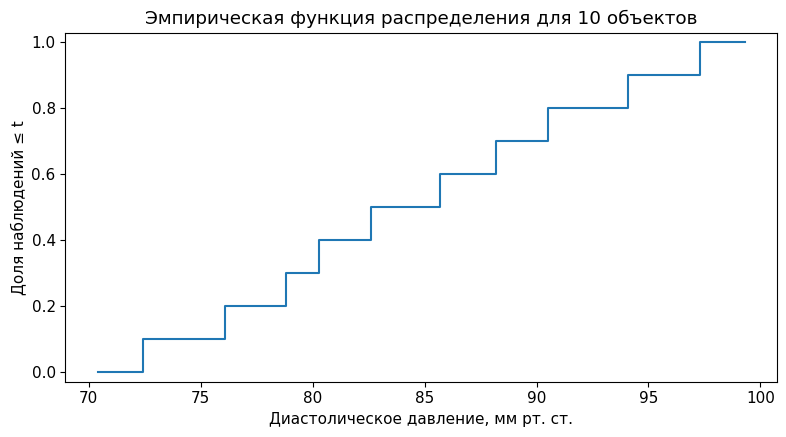

In [10]:
plt.figure()
plt.step(np.r_[ordered[0] - 2, ordered, ordered[-1] + 2],
         np.r_[0, np.arange(1, len(x) + 1) / len(x), 1], where='post')
plt.xlabel('Диастолическое давление, мм рт. ст.')
plt.ylabel('Доля наблюдений ≤ t')
plt.title('Эмпирическая функция распределения для 10 объектов')
plt.ylim(-0.03, 1.03)
plt.tight_layout()
plt.show()

<a id="distributions"></a>
## 3. Генеральная совокупность и распределения

Назовём генеральной совокупностью все объекты, о которых предполагается сделать вывод в исследовании. Например, это могут быть взрослые жители выбранного региона на определённую дату. Для сопоставимости измерений потребуется единый порядок обследования. Обычно исследователь располагает сведениями лишь о части объектов, образующей выборку. Поэтому при оценке результатов необходимо учитывать способ отбора.

Вероятностная модель описывает возможные результаты выбора объекта или повторного измерения. В дальнейших расчётах примем независимость наблюдений и одинаковый закон их распределения. Эти предположения задают условия рассматриваемых опытов. Выборка без возвращения из конечной совокупности требует отдельного учёта зависимости между наблюдениями.

### 3.1. Функция вероятностей и плотность

Для дискретной случайной величины $\xi$ каждому допустимому значению $r$ сопоставляется вероятность $p(r)=P(\xi=r)$. Сумма этих вероятностей равна единице. В SciPy их вычисляет метод `pmf`.

Для непрерывной величины вероятность попадания в интервал находят по плотности $f(t)\ge0$.
$$P(a<\xi\le b)=\int_a^b f(t)\,dt=F(b)-F(a),\qquad F(t)=P(\xi\le t).$$
Интеграл выражает площадь под графиком плотности на выбранном интервале. Функция $F(t)$ называется функцией распределения. Для закона с плотностью вероятность отдельной точки равна нулю.

В SciPy метод `pdf` вычисляет плотность, `cdf` — значение функции распределения, `sf` — вероятность превысить заданную границу. Метод `ppf` находит квантиль заданного уровня.

При округлении измерений одному показанию прибора соответствует целый интервал исходных значений. Для такого показания будем вычислять вероятность соответствующего интервала.

### 3.2. Распределение Бернулли

Пусть испытание имеет два возможных результата, обозначенные числами 0 и 1. Если вероятность единицы равна $p$, случайная величина $\xi$ имеет распределение Бернулли, что записывается как $\xi\sim\operatorname{Bern}(p)$.
$$P(\xi=r)=p^r(1-p)^{1-r},\quad r\in\{0,1\},\quad 0\le p\le1.$$
Для остальных значений вероятность равна нулю. Математическое ожидание этого закона равно $p$, а дисперсия равна $p(1-p)$. Эти характеристики описывают средний уровень и разброс значений в модели. Их общие определения рассмотрим в разделе 4.

Справка. [scipy.stats.bernoulli](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bernoulli.html).

In [11]:
values = np.random.binomial(1, 0.2, 100)

print(values)
print(np.where(values == 1, "A", "B"))

[1 1 0 0 0 0 1 0 1 0 1 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 1
 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 1 0 1 0 0 1 0 0 0 0 1 0 0 1
 0 1 0 0 0 1 0 0 1 0 1 0 0 0 0 1 0 0 1 0 0 0 0 0 1 0]
['A' 'A' 'B' 'B' 'B' 'B' 'A' 'B' 'A' 'B' 'A' 'B' 'A' 'B' 'A' 'B' 'B' 'B'
 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'A' 'B'
 'A' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'A' 'B' 'B' 'B' 'A' 'B' 'B' 'B'
 'B' 'B' 'B' 'B' 'A' 'B' 'A' 'B' 'A' 'B' 'B' 'A' 'B' 'B' 'B' 'B' 'A' 'B'
 'B' 'A' 'B' 'A' 'B' 'B' 'B' 'A' 'B' 'B' 'A' 'B' 'A' 'B' 'B' 'B' 'B' 'A'
 'B' 'B' 'A' 'B' 'B' 'B' 'B' 'B' 'A' 'B']


In [12]:
def bernoulli_pmf(values, p):
    if not 0 <= p <= 1:
        raise ValueError('Нужно 0 ≤ p ≤ 1.')
    values = np.asarray(values)
    return np.where(values == 1, p, np.where(values == 0, 1 - p, 0.0))

p = 0.2
print('Вероятности для 0 и 1:', bernoulli_pmf([0, 1], p))
rng_bern = np.random.default_rng(101)
bern_sample = rng_bern.binomial(1, p, size=10_000)
print('Наблюдаемая доля единиц:', bern_sample.mean())
np.testing.assert_allclose(bernoulli_pmf([0, 1], p), stats.bernoulli.pmf([0, 1], p))

Вероятности для 0 и 1: [0.8 0.2]
Наблюдаемая доля единиц: 0.2029


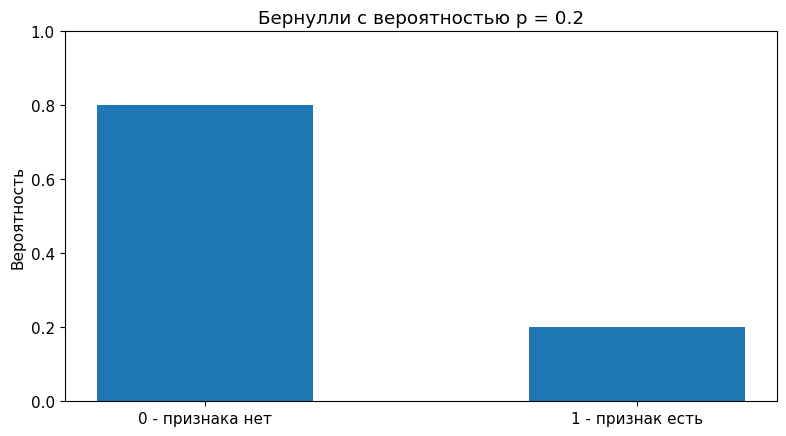

In [13]:
plt.figure()
plt.bar([0, 1], bernoulli_pmf([0, 1], p), width=0.5)
plt.xticks([0, 1], ['0 - признака нет', '1 - признак есть'])
plt.ylabel('Вероятность')
plt.title('Бернулли с вероятностью p = 0.2')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### 3.3. Биномиальное распределение

Повторим испытание Бернулли $N$ раз независимо при одной и той же вероятности успеха $p$. Число успехов имеет биномиальное распределение
$$P(\xi=r)=\binom Nr p^r(1-p)^{N-r},\quad r=0,\ldots,N.$$
Буква $N$ обозначает число испытаний, результаты которых складываются в одном опыте. Для полученной величины $E\xi=Np$ и $\operatorname{Var}\xi=Np(1-p)$. При $N=1$ формула переходит в закон Бернулли. Рассчитаем вероятности разных чисел успехов.

Справка. [scipy.stats.binom](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html).

In [14]:
# Справка-пример по списковым выражениям
print("Пример 1:", [i**2 for i in range(-5, 6)])
print("Пример 2:", [f"{k} + {m} = {k+m}" for k, m in enumerate([1, 3, 4])])
print("Пример 3:", [3 * i for i in range(10) if i % 2==0])
print("Пример 4:", [math.comb(2*m, m) if (0 <= m <= 5) else 0.0 for m in range(-1, 8)])

Пример 1: [25, 16, 9, 4, 1, 0, 1, 4, 9, 16, 25]
Пример 2: ['0 + 1 = 1', '1 + 3 = 4', '2 + 4 = 6']
Пример 3: [0, 6, 12, 18, 24]
Пример 4: [0.0, 1, 2, 6, 20, 70, 252, 0.0, 0.0]


In [15]:
def binomial_pmf(values, trials, p):
    values = np.asarray(values)
    returning = np.array(
        [
            math.comb(trials, int(r)) * (p**r) * ((1 - p)**(trials - r)) 
            if (0 <= r <= trials) and (r == int(r)) else 0.0
            for r in values.ravel()
        ]
    )
    return returning.reshape(values.shape)

r_binom = np.arange(11)
prob_binom = binomial_pmf(r_binom, 10, 0.2)

print('P(ровно 2 успеха):', prob_binom[2])
print('P(от 1 до 3 успехов):', prob_binom[1:4].sum())
np.testing.assert_allclose(prob_binom, stats.binom.pmf(r_binom, 10, 0.2))

P(ровно 2 успеха): 0.3019898880000002
P(от 1 до 3 успехов): 0.7717519360000005


Частота ровно 2 успехов: 0.2952


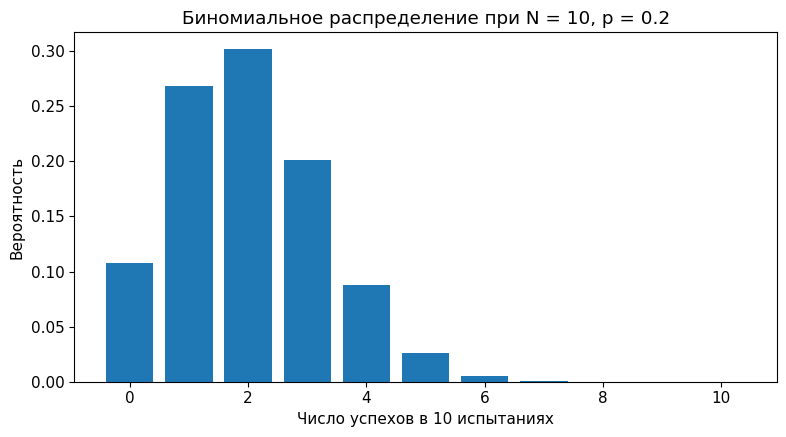

In [16]:
rng_binom = np.random.default_rng(102)
binom_sample = rng_binom.binomial(10, 0.2, size=10_000)
print('Частота ровно 2 успехов:', np.mean(binom_sample == 2))

plt.figure()
plt.bar(r_binom, prob_binom)
plt.xlabel('Число успехов в 10 испытаниях')
plt.ylabel('Вероятность')
plt.title('Биномиальное распределение при N = 10, p = 0.2')
plt.tight_layout()
plt.show()

### 3.4. Распределение Пуассона

Для описания числа событий за фиксированное время часто рассматривают распределение Пуассона
$$P(\xi=r)=e^{-\lambda}\frac{\lambda^r}{r!},\quad r=0,1,\ldots,\quad\lambda\ge0.$$
У этого закона математическое ожидание и дисперсия равны одному параметру $\lambda$. В модели потока независимых событий с постоянной интенсивностью $\rho$ за время $t$ получаем $\lambda=\rho t$. Применение такой модели к наблюдаемому счётчику требует проверки условий, в которых возникли события.

Для больших $r$ удобнее вычислять логарифм факториала. Воспользуемся равенством $\log(r!)=\log\Gamma(r+1)$ и функцией `gammaln`.

Справка. [scipy.stats.poisson](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html).

In [17]:
def poisson_pmf(values, rate):
    if rate < 0:
        raise ValueError('Нужно λ ≥ 0.')
    values = np.asarray(values, dtype=float)
    valid = (values >= 0) & (values == np.floor(values))
    safe = np.where(valid, values, 0.0)
    if rate == 0:
        return (values == 0).astype(float)
    result = np.exp(-rate + safe * np.log(rate) - gammaln(safe + 1))
    return np.where(valid, result, 0.0)

print('P(ровно 3 события):', poisson_pmf(3, 2.5))
print('P(не более 2 событий):', poisson_pmf(np.arange(3), 2.5).sum())

np.testing.assert_allclose(poisson_pmf(np.arange(15), 2.5), stats.poisson.pmf(np.arange(15), 2.5))

P(ровно 3 события): 0.21376301724973648
P(не более 2 событий): 0.5438131158833295


Частота не более 2 событий: 0.5439


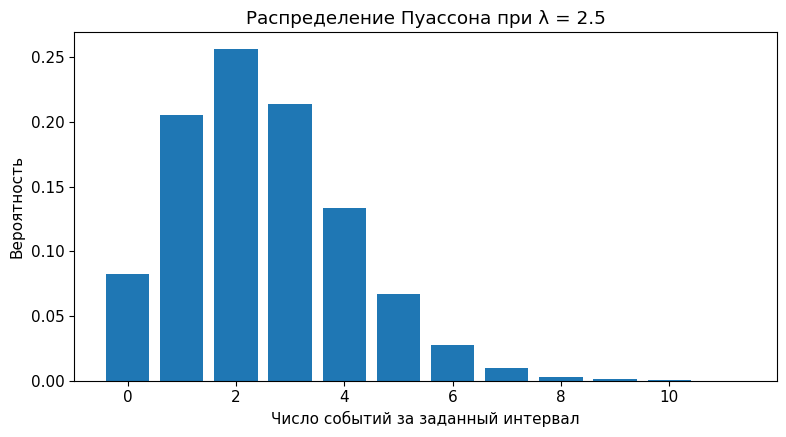

In [18]:
rng_pois = np.random.default_rng(103)
pois_sample = rng_pois.poisson(2.5, size=10_000)
print('Частота не более 2 событий:', np.mean(pois_sample <= 2))

plt.figure()
plt.bar(np.arange(12), poisson_pmf(np.arange(12), 2.5))
plt.xlabel('Число событий за заданный интервал')
plt.ylabel('Вероятность')
plt.title('Распределение Пуассона при λ = 2.5')
plt.tight_layout()
plt.show()

### 3.5. Равномерное распределение

Случайная величина $\xi\sim U(a,b)$, где $a<b$, имеет постоянную плотность на отрезке $[a,b]$.
$$f(t)=\frac{1}{b-a}\mathbf1\{a\le t\le b\}.$$
Для подынтервала внутри этого отрезка вероятность равна отношению его длины к $b-a$. Математическое ожидание равно $(a+b)/2$, дисперсия равна $(b-a)^2/12$.

В SciPy начало отрезка задаётся как `loc=a`, а его длина как `scale=b-a`.

Справка. [scipy.stats.uniform](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html).

In [19]:
def uniform_pdf(values, a, b):
    if not a < b:
        raise ValueError('Нужно a < b.')
    values = np.asarray(values)
    return np.where((a <= values) & (values <= b), 1 / (b - a), 0.0)

prob_uniform = (6 - 2) / (10 - 0)
rng_uniform = np.random.default_rng(104)
uniform_sample = rng_uniform.uniform(0, 10, size=10_000)
print('P(2 ≤ ξ ≤ 6):', prob_uniform)
print('Частота:', np.mean((uniform_sample >= 2) & (uniform_sample <= 6)))

np.testing.assert_allclose(uniform_pdf([-1, 0, 5, 11], 0, 10),
                           stats.uniform.pdf([-1, 0, 5, 11], loc=0, scale=10))

P(2 ≤ ξ ≤ 6): 0.4
Частота: 0.3981


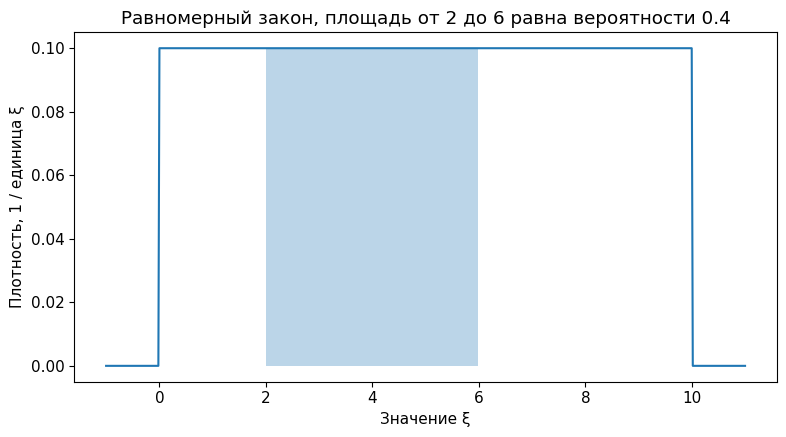

In [20]:
grid_uniform = np.linspace(-1, 11, 600)

plt.figure()
plt.plot(grid_uniform, uniform_pdf(grid_uniform, 0, 10))
plt.fill_between(grid_uniform, uniform_pdf(grid_uniform, 0, 10),
                 where=(grid_uniform >= 2) & (grid_uniform <= 6), alpha=0.3)
plt.xlabel('Значение ξ')
plt.ylabel('Плотность, 1 / единица ξ')
plt.title('Равномерный закон, площадь от 2 до 6 равна вероятности 0.4')
plt.tight_layout()
plt.show()

### 3.6. Нормальное распределение

Нормальное распределение $\xi\sim N(\mu,\sigma^2)$ при $\sigma>0$ задаётся плотностью
$$f(t)=\frac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(t-\mu)^2}{2\sigma^2}\right],\quad t\in\mathbb R.$$
Параметр $\mu$ является математическим ожиданием, а $\sigma^2$ — дисперсией. График плотности симметричен относительно $\mu$ и определён на всей числовой прямой. Для учебного примера давления примем значения $\mu=80$ и $\sigma=8$.

При вызове генератора NumPy или функций SciPy в аргументе `scale` указывается стандартное отклонение $\sigma$. Вычислим плотность и вероятности нескольких интервалов.

Справка. [scipy.stats.norm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html).

In [21]:
def normal_pdf(values, mean, std):
    if np.any(np.asarray(std) <= 0):
        raise ValueError('Стандартное отклонение должно быть положительным.')
    values = np.asarray(values)
    return np.exp(-0.5 * ((values - mean) / std) ** 2) / (std * np.sqrt(2 * np.pi))

mu_demo, sigma_demo = 80.0, 8.0
prob_normal = stats.norm.cdf(90, mu_demo, sigma_demo) - stats.norm.cdf(80, mu_demo, sigma_demo)
print('Плотность в точке 85:', normal_pdf(85, mu_demo, sigma_demo))
print('P(80 ≤ ξ ≤ 90):', prob_normal)

rng_normal = np.random.default_rng(105)
normal_sample = rng_normal.normal(mu_demo, sigma_demo, size=10_000)
print('Частота интервала:', np.mean((80 <= normal_sample) & (normal_sample <= 90)))

Плотность в точке 85: 0.041020121068796885
P(80 ≤ ξ ≤ 90): 0.39435022633314465
Частота интервала: 0.3961


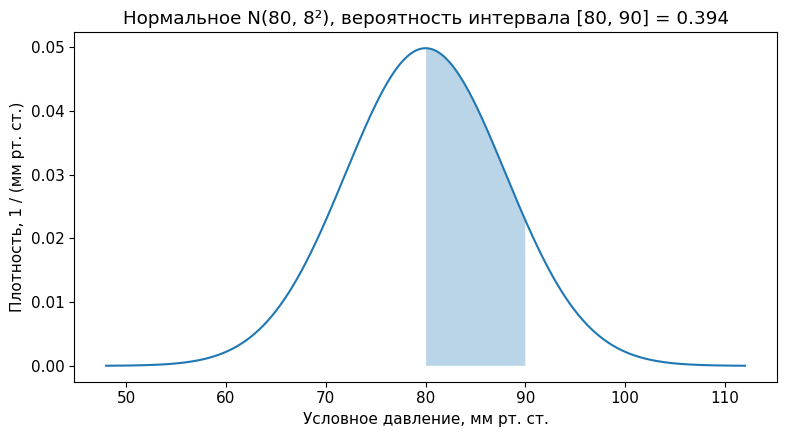

In [22]:
grid_normal = np.linspace(48, 112, 600)
np.testing.assert_allclose(normal_pdf(grid_normal, 80, 8), stats.norm.pdf(grid_normal, 80, 8))

plt.figure()
plt.plot(grid_normal, normal_pdf(grid_normal, 80, 8))
plt.fill_between(grid_normal, normal_pdf(grid_normal, 80, 8),
                 where=(grid_normal >= 80) & (grid_normal <= 90), alpha=0.3)
plt.xlabel('Условное давление, мм рт. ст.')
plt.ylabel('Плотность, 1 / (мм рт. ст.)')
plt.title(f'Нормальное N(80, 8²), вероятность интервала [80, 90] = {prob_normal:.3f}')
plt.tight_layout()
plt.show()

### 3.7. Логнормальное распределение

Пусть $Z\sim N(\mu_{\log},\sigma_{\log}^2)$. Величину $\xi=e^Z$ называют логнормальной. Её плотность при положительных значениях имеет вид
$$f(t)=\frac{1}{t\sigma_{\log}\sqrt{2\pi}}
\exp\!\left[-\frac{(\log t-\mu_{\log})^2}{2\sigma_{\log}^2}\right],\quad t>0.$$
При $t\le0$ плотность равна нулю. Параметры $\mu_{\log}$ и $\sigma_{\log}^2$ задают распределение логарифма величины. Для самой $\xi$ получаем
$$E\xi=e^{\mu_{\log}+\sigma_{\log}^2/2},\qquad
\operatorname{Var}\xi=(e^{\sigma_{\log}^2}-1)e^{2\mu_{\log}+\sigma_{\log}^2}.$$
Медиана равна $e^{\mu_{\log}}$. Если исходная величина имеет единицы измерения, перед логарифмированием фиксируют их и используют численное значение в этих единицах.

В SciPy параметры задаются как `s=σ_log`, `scale=exp(μ_log)` и `loc=0`.

Справка. [scipy.stats.lognorm](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.lognorm.html).

In [23]:
def lognormal_pdf(values, mean_log, std_log):
    if std_log <= 0:
        raise ValueError('Нужно σ_log > 0.')
    values = np.asarray(values, dtype=float)
    safe = np.where(values > 0, values, 1.0)
    density = normal_pdf(np.log(safe), mean_log, std_log) / safe
    return np.where(values > 0, density, 0.0)

mu_log_demo, sigma_log_demo = np.log(45), 0.3
law_age = stats.lognorm(s=sigma_log_demo, scale=np.exp(mu_log_demo))
print('P(40 ≤ ξ ≤ 50):', law_age.cdf(50) - law_age.cdf(40))

rng_lognormal = np.random.default_rng(106)
lognormal_sample = rng_lognormal.lognormal(mu_log_demo, sigma_log_demo, size=10_000)
print('Частота интервала:', np.mean((40 <= lognormal_sample) & (lognormal_sample <= 50)))

P(40 ≤ ξ ≤ 50): 0.2899777572815124
Частота интервала: 0.2921


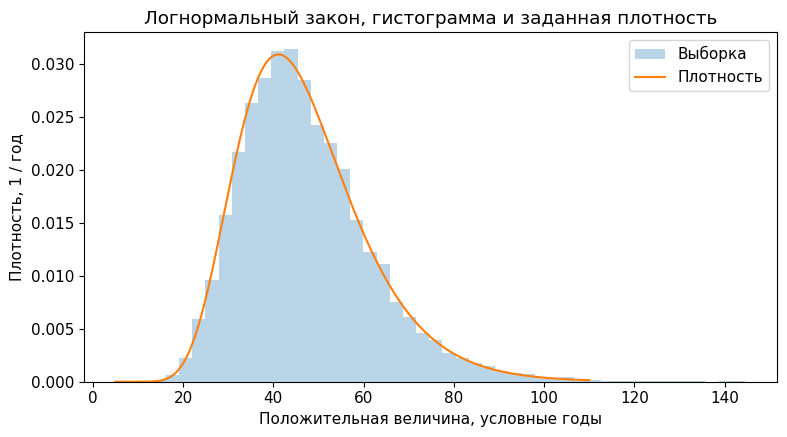

In [24]:
grid_age = np.linspace(5, 110, 600)

plt.figure()
plt.hist(lognormal_sample, bins=45, density=True, alpha=0.3, label='Выборка')
plt.plot(grid_age, lognormal_pdf(grid_age, mu_log_demo, sigma_log_demo), label='Плотность')
plt.xlabel('Положительная величина, условные годы')
plt.ylabel('Плотность, 1 / год')
plt.title('Логнормальный закон, гистограмма и заданная плотность')
plt.legend()
plt.tight_layout()
plt.show()

### 3.8. Экспоненциальное распределение

Экспоненциальное распределение $\xi\sim\operatorname{Exp}(\lambda)$ при $\lambda>0$ задаётся плотностью и функцией распределения
$$f(t)=\lambda e^{-\lambda t}\mathbf1\{t\ge0\},\qquad
F(t)=1-e^{-\lambda t}\quad(t\ge0).$$
Математическое ожидание равно $1/\lambda$, дисперсия равна $1/\lambda^2$. Этот закон описывает, например, время ожидания следующего события в пуассоновском потоке с постоянной интенсивностью. В SciPy параметр масштаба задаётся как `scale=1/λ`.

Рассмотрим график плотности и вычислим вероятность ожидания дольше заданного времени.

Справка. [scipy.stats.expon](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html).

In [25]:
def exponential_pdf(values, rate):
    if rate <= 0:
        raise ValueError('Нужно λ > 0.')
    values = np.asarray(values)
    safe = np.maximum(values, 0)
    return np.where(values >= 0, rate * np.exp(-rate * safe), 0.0)

rate_exp = 0.2
print('P(2 ≤ ξ ≤ 5):', np.exp(-rate_exp * 2) - np.exp(-rate_exp * 5))

rng_exp = np.random.default_rng(107)
exp_sample = rng_exp.exponential(scale=1 / rate_exp, size=10_000)
print('Частота интервала:', np.mean((2 <= exp_sample) & (exp_sample <= 5)))

np.testing.assert_allclose(exponential_pdf([0, 1, 5], rate_exp),
                           stats.expon.pdf([0, 1, 5], scale=1 / rate_exp))

P(2 ≤ ξ ≤ 5): 0.302440604864197
Частота интервала: 0.3027


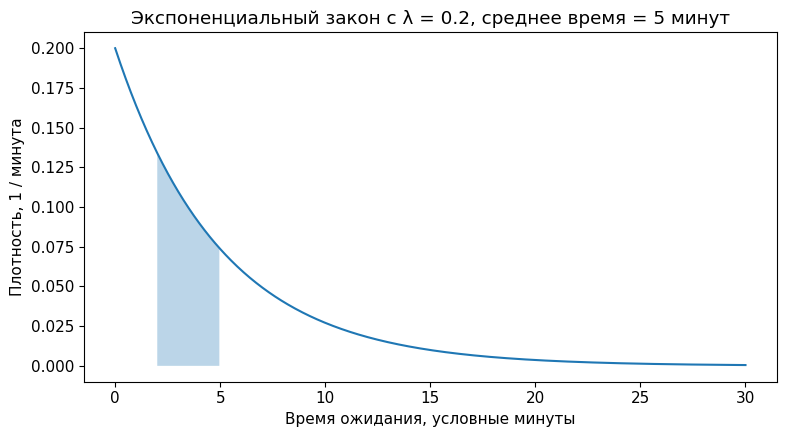

In [26]:
grid_exp = np.linspace(0, 30, 600)
plt.figure()
plt.plot(grid_exp, exponential_pdf(grid_exp, rate_exp))
plt.fill_between(grid_exp, exponential_pdf(grid_exp, rate_exp),
                 where=(grid_exp >= 2) & (grid_exp <= 5), alpha=0.3)
plt.xlabel('Время ожидания, условные минуты')
plt.ylabel('Плотность, 1 / минута')
plt.title('Экспоненциальный закон с λ = 0.2, среднее время = 5 минут')
plt.tight_layout()
plt.show()

In [27]:
from scipy.integrate import quad
normalization = pd.Series({
    'Бернулли': bernoulli_pmf([0, 1], 0.2).sum(),
    'Биномиальное': binomial_pmf(np.arange(11), 10, 0.2).sum(),
    'Пуассон: сумма + хвост': poisson_pmf(np.arange(31), 2.5).sum() + stats.poisson.sf(30, 2.5),
    'Равномерное': quad(lambda z: uniform_pdf(z, 0, 10), 0, 10)[0],
    'Нормальное': quad(lambda z: normal_pdf(z, 80, 8), -np.inf, np.inf)[0],
    'Логнормальное': quad(lambda z: lognormal_pdf(z, np.log(45), 0.3), 0, np.inf)[0],
    'Экспоненциальное': quad(lambda z: exponential_pdf(z, 0.2), 0, np.inf)[0],
}, name='Полная вероятность')
display(normalization)

Бернулли                  1.0
Биномиальное              1.0
Пуассон: сумма + хвост    1.0
Равномерное               1.0
Нормальное                1.0
Логнормальное             1.0
Экспоненциальное          1.0
Name: Полная вероятность, dtype: float64

<a id="estimation"></a>
## 4. Параметры распределения и их оценки

### 4.1. Математическое ожидание и выборочное среднее

Математическим ожиданием случайной величины называют среднее её возможных значений, взятых с учётом их вероятностей. Для дискретного закона используется сумма, а для закона с плотностью — интеграл.
$$
E\xi=\sum_r rP(\xi=r)\quad\text{или}\quad
E\xi=\int_{-\infty}^{\infty}t f(t)\,dt,
$$
Предполагается конечность соответствующей суммы или интеграла от абсолютных значений. По наблюдениям $x_1,\ldots,x_n$ параметр $\mu=E\xi$ оценивают выборочным средним $\bar x$.

Закон больших чисел устанавливает сходимость выборочного среднего к $\mu$ при независимых одинаково распределённых наблюдениях и конечном $E|\xi|$. Рассмотрим, как ведёт себя среднее при последовательном добавлении наблюдений.

В следующем опыте зададим нормальный и экспоненциальный законы с одинаковыми ожиданием 10 и дисперсией 100. Сравним полученные последовательности средних. Здесь нормальная величина служит числовым примером и может принимать отрицательные значения.

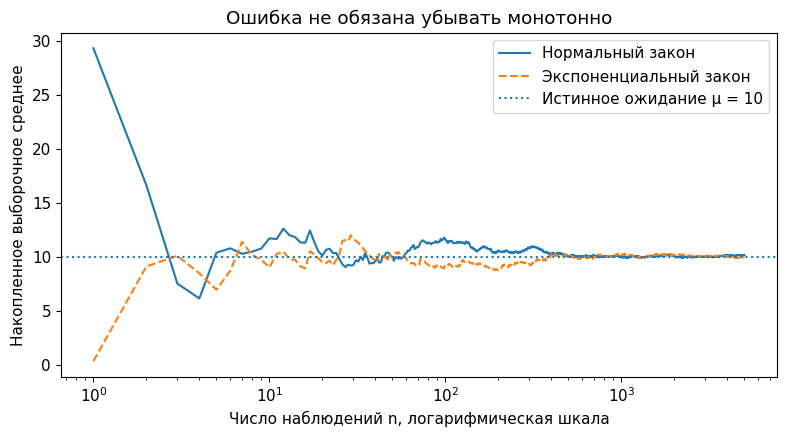

In [28]:
rng_means = np.random.default_rng(201)

size_path = 5_000
normal_path = rng_means.normal(10, 10, size_path)
exp_path = rng_means.exponential(10, size_path)
counts_path = np.arange(1, size_path + 1)

plt.figure()
plt.plot(counts_path, normal_path.cumsum() / counts_path, label='Нормальный закон')
plt.plot(counts_path, exp_path.cumsum() / counts_path, label='Экспоненциальный закон', linestyle='--')
plt.axhline(10, linestyle=':', label='Истинное ожидание μ = 10')
plt.xscale('log')
plt.xlabel('Число наблюдений n, логарифмическая шкала')
plt.ylabel('Накопленное выборочное среднее')
plt.title('Ошибка не обязана убывать монотонно')
plt.legend()
plt.tight_layout()
plt.show()

### 4.2. Стандартная ошибка среднего

Дисперсия случайной величины определяется как математическое ожидание квадрата её отклонения от $\mu$.
$$\sigma^2=\operatorname{Var}\xi=E[(\xi-\mu)^2],\qquad \sigma=\sqrt{\sigma^2}.$$
Выборочное среднее тоже является случайной величиной. Для независимых одинаково распределённых наблюдений с конечной дисперсией справедливы равенства
$$E\bar X=\mu,\qquad \operatorname{Var}\bar X=\frac{\sigma^2}{n},\qquad
\operatorname{SE}(\bar X)=\frac{\sigma}{\sqrt n}.$$
Стандартное отклонение выборочного среднего называют его стандартной ошибкой. Когда $\sigma$ неизвестно, её оценивают величиной $s/\sqrt n$.

Вычислим средние по многим выборкам одинакового объёма. Сопоставим их разброс с формулой стандартной ошибки. Для нормального и экспоненциального законов сравним также форму распределения этих средних.

In [29]:
rng_repeat = np.random.default_rng(202)
repeats = 4_000
rows_means = []
for sample_size in [5, 10, 30, 100, 500]:
    for name in ['Нормальное', 'Экспоненциальное']:
        samples = (rng_repeat.normal(10, 10, (repeats, sample_size)) if name == 'Нормальное'
                   else rng_repeat.exponential(10, (repeats, sample_size)))
        means = samples.mean(axis=1)
        rows_means.append([name, sample_size, means.mean(), means.std(ddof=1),
                           np.sqrt(np.mean((means - 10)**2)), 10 / np.sqrt(sample_size)])
means_summary = pd.DataFrame(rows_means, columns=['закон', 'n', 'среднее оценок',
                                                 'разброс оценок', 'RMSE', 'теоретическая SE'])
display(means_summary)

,закон,n,среднее оценок,разброс оценок,RMSE,теоретическая SE
0,Нормальное,5,9.9658,4.5654,4.5649,4.4721
1,Экспоненциальное,5,10.1108,4.4598,4.4606,4.4721
2,Нормальное,10,9.9054,3.1645,3.1655,3.1623
3,Экспоненциальное,10,9.9655,3.1183,3.1181,3.1623
4,Нормальное,30,10.0132,1.8258,1.8256,1.8257
5,Экспоненциальное,30,9.9815,1.8013,1.8012,1.8257
6,Нормальное,100,10.0209,1.0086,1.0087,1.0000
7,Экспоненциальное,100,10.0055,0.9938,0.9937,1.0000
8,Нормальное,500,9.9989,0.4488,0.4488,0.4472
9,Экспоненциальное,500,9.9919,0.4443,0.4443,0.4472


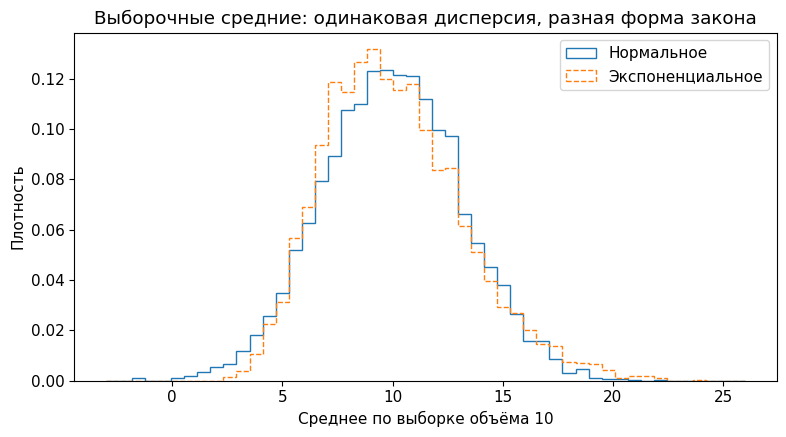

In [30]:
rng_mean_shape = np.random.default_rng(203)
means_normal_10 = rng_mean_shape.normal(10, 10, (5_000, 10)).mean(axis=1)
means_exp_10 = rng_mean_shape.exponential(10, (5_000, 10)).mean(axis=1)
shared_bins = np.linspace(-3, 26, 50)
plt.figure()
plt.hist(means_normal_10, bins=shared_bins, density=True, histtype='step', label='Нормальное')
plt.hist(means_exp_10, bins=shared_bins, density=True, histtype='step', linestyle='--', label='Экспоненциальное')
plt.xlabel('Среднее по выборке объёма 10')
plt.ylabel('Плотность')
plt.title('Выборочные средние: одинаковая дисперсия, разная форма закона')
plt.legend()
plt.tight_layout()
plt.show()

### 4.3. Обоснование делителя n−1

Пусть независимые одинаково распределённые $X_i$ имеют ожидание $\mu$ и конечную дисперсию $\sigma^2$. Начнём с тождества
$$\sum_i(X_i-\bar X)^2=\sum_i(X_i-\mu)^2-n(\bar X-\mu)^2.$$
Возьмём математическое ожидание обеих частей и воспользуемся равенством $\operatorname{Var}\bar X=\sigma^2/n$.
$$E\sum_i(X_i-\bar X)^2=n\sigma^2-n\frac{\sigma^2}{n}=(n-1)\sigma^2.$$
Отсюда $E[v_n]=(n-1)\sigma^2/n$ и $E[s^2]=\sigma^2$. Оценку называют несмещённой, если её математическое ожидание равно оцениваемому параметру. Таким свойством обладает исправленная выборочная дисперсия $s^2$ при сделанных предположениях.

Для оценки стандартного отклонения берут $s=\sqrt{s^2}$. Свойства этой оценки требуют отдельного рассмотрения, поскольку математическое ожидание квадратного корня зависит от распределения $s^2$. Сравним оценки в опыте с повторными выборками.

In [31]:
rng_variance = np.random.default_rng(204)
variance_samples = rng_variance.normal(80, 8, size=(20_000, 8))
variance_comparison = pd.Series({
    'Истинная σ²': 8**2,
    'Среднее v_n': variance_samples.var(axis=1, ddof=0).mean(),
    'Теория E[v_n]': 7 / 8 * 8**2,
    'Среднее s²': variance_samples.var(axis=1, ddof=1).mean(),
    'Истинная σ': 8,
    'Среднее s': variance_samples.std(axis=1, ddof=1).mean(),
})
display(variance_comparison)

Истинная σ²      64.0000
Среднее v_n      55.7928
Теория E[v_n]    56.0000
Среднее s²       63.7632
Истинная σ        8.0000
Среднее s         7.7027
dtype: float64

### 4.4. Подбор распределения по оценённым параметрам

Предположим, что наблюдения в рассматриваемой группе независимы и имеют общий нормальный закон. Оценки максимального правдоподобия равны
$$\hat\mu=\bar x,\qquad \hat\sigma^2_{\mathrm{ML}}=\frac1n\sum_i(x_i-\bar x)^2.$$
При фиксированных данных произведение $L(\theta)=\prod_i f(x_i;\theta)$ рассматривают как функцию параметров $\theta$. Оно называется функцией правдоподобия. Метод максимального правдоподобия выбирает параметры, при которых это произведение достигает наибольшего значения.

Подставим оценки в формулу плотности и построим её график. Далее для доверительных интервалов будем использовать исправленную дисперсию с делителем $n-1$. При обучении гауссовского наивного Байеса применяется приведённая здесь оценка максимального правдоподобия с делителем $n$.

In [32]:
rng_fit = np.random.default_rng(205)
fit_sample = rng_fit.normal(80, 8, size=60)
mean_hat = fit_sample.mean()
std_hat_ml = fit_sample.std(ddof=0)
std_hat_unbiased_var = fit_sample.std(ddof=1)
display(pd.DataFrame({
    'параметр': ['μ', 'σ²'],
    'истина': [80, 64],
    'оценка ML': [mean_hat, std_hat_ml**2],
    'с исправленной дисперсией': [mean_hat, std_hat_unbiased_var**2],
}))

,параметр,истина,оценка ML,с исправленной дисперсией
0,μ,80,80.0495,80.0495
1,σ²,64,78.3816,79.7101


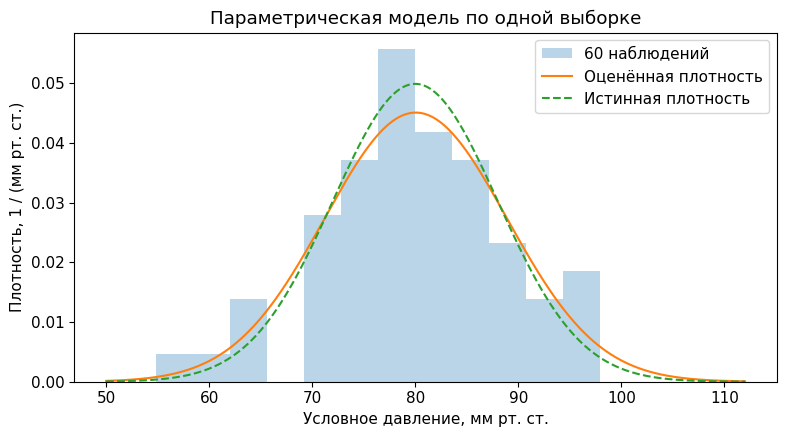

In [33]:
grid_fit = np.linspace(50, 112, 600)
plt.figure()
plt.hist(fit_sample, bins=12, density=True, alpha=0.3, label='60 наблюдений')
plt.plot(grid_fit, normal_pdf(grid_fit, mean_hat, std_hat_ml), label='Оценённая плотность')
plt.plot(grid_fit, normal_pdf(grid_fit, 80, 8), linestyle='--', label='Истинная плотность')
plt.xlabel('Условное давление, мм рт. ст.')
plt.ylabel('Плотность, 1 / (мм рт. ст.)')
plt.title('Параметрическая модель по одной выборке')
plt.legend()
plt.tight_layout()
plt.show()

Сопоставьте гистограмму с построенной плотностью. Измените число интервалов гистограммы и проследите, какие особенности сохраняются. В этом опыте исходный закон известен по условию генерации. При работе с реальными данными выбор модели требует учёта способа измерения, отбора объектов и различий между группами.

Для логнормальной модели находят среднее и дисперсию логарифмов наблюдений. Для экспоненциальной модели с нулевым сдвигом оценка интенсивности равна $\hat\lambda=1/\bar x$. Подставив оценки в параметры генератора, можно получить новую искусственную выборку по подобранной модели.

In [34]:
log_values = np.log(lognormal_sample)
log_mean_hat = log_values.mean()
log_std_hat = log_values.std(ddof=0)
rate_hat = 1 / exp_sample.mean()
rng_resimulate = np.random.default_rng(206)
model_values = rng_resimulate.lognormal(log_mean_hat, log_std_hat, size=5)
print('Оценки параметров логарифма:', log_mean_hat, log_std_hat)
print('Оценка интенсивности Exp:', rate_hat)
print('Пять модельных, а не наблюдавшихся значений:', model_values)

Оценки параметров логарифма: 3.811674741291359 0.3011980322476103
Оценка интенсивности Exp: 0.20069186657303506
Пять модельных, а не наблюдавшихся значений: [55.69783447 43.99244436 68.56303389 52.77754228 42.52596286]


<a id="intervals"></a>
## 5. Доверительные интервалы

При повторном получении выборки оценка параметра меняется. Чтобы выразить точность оценивания, наряду с отдельным числом указывают интервал. Его границы $L(X)$ и $U(X)$ вычисляются по выборке. Для доверительного уровня $1-\alpha$ способ построения выбирают так, чтобы
$$P_\theta\{L(X)\le\theta\le U(X)\}=1-\alpha$$
В точной процедуре равенство выполняется в принятой модели. При использовании приближённого распределения оно служит приближённым соотношением.

Параметр $\theta$ здесь фиксирован и неизвестен. От выборки к выборке меняются границы интервала. Смысл доверительного уровня рассмотрим на многократном повторении опыта.

Сначала введём два распределения, с помощью которых строятся интервалы для нормальных наблюдений. Начнём с суммы квадратов стандартных нормальных величин, затем перейдём к отношению Стьюдента.

### 5.1. Распределение χ² как сумма квадратов

Пусть $Z_1,\ldots,Z_\nu$ независимы и имеют стандартное нормальное распределение. Сумма их квадратов имеет распределение χ².
$$U=\sum_{j=1}^{\nu}Z_j^2\sim\chi^2_\nu.$$
Число $\nu$ называют числом степеней свободы. В данном построении оно совпадает с числом слагаемых. Плотность при $u>0$ задаётся формулой
$$f_\nu(u)=\frac{u^{\nu/2-1}e^{-u/2}}{2^{\nu/2}\Gamma(\nu/2)}.$$
Эта формула определена при любом вещественном $\nu>0$. Математическое ожидание равно $EU=\nu$, дисперсия равна $\operatorname{Var}U=2\nu$.

В знаменателе используется гамма-функция $\Gamma(a)=\int_0^\infty t^{a-1}e^{-t}\,dt$. При целом $q\ge1$ она удовлетворяет равенству $\Gamma(q)=(q-1)!$. Получим выборку по определению и сравним её гистограмму с плотностью.

Справка. [Распределение χ² в SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html), [NIST — конструкция и свойства](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3666.htm).

In [35]:
nu_demo = 5
rng_chi = np.random.default_rng(301)
z_chi = rng_chi.normal(size=(40_000, nu_demo))
chi_from_definition = (z_chi ** 2).sum(axis=1)
print('Среднее: опыт / теория:', chi_from_definition.mean(), nu_demo)
print('Дисперсия: опыт / теория:', chi_from_definition.var(), 2 * nu_demo)

Среднее: опыт / теория: 4.993210524191249 5
Дисперсия: опыт / теория: 9.908509477150108 10


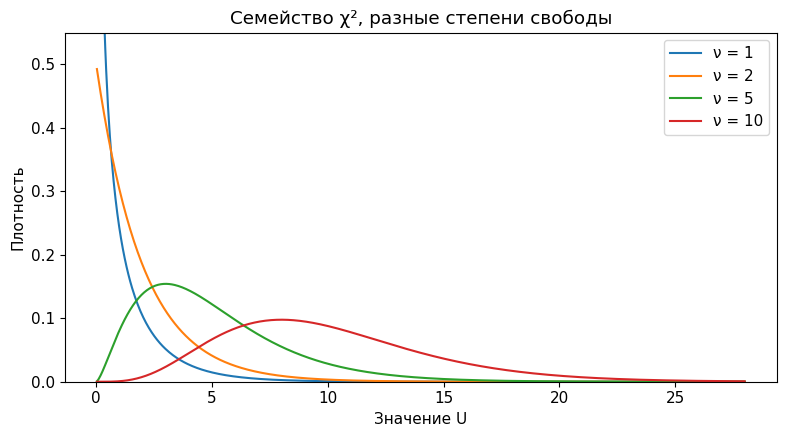

In [36]:
grid_chi = np.linspace(0.03, 28, 700)
plt.figure()
for degrees in [1, 2, 5, 10]:
    plt.plot(grid_chi, stats.chi2.pdf(grid_chi, df=degrees), label=f'ν = {degrees}')
plt.xlabel('Значение U')
plt.ylabel('Плотность')
plt.ylim(0, 0.55)
plt.title('Семейство χ², разные степени свободы')
plt.legend()
plt.tight_layout()
plt.show()

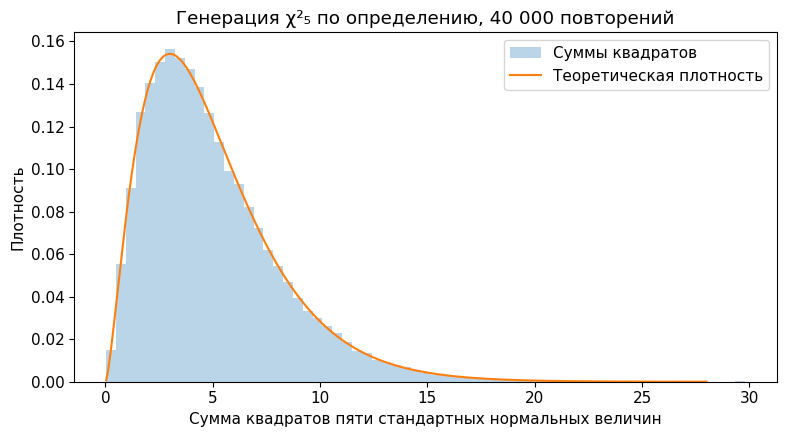

In [37]:
plt.figure()
plt.hist(chi_from_definition, bins=65, density=True, alpha=0.3, label='Суммы квадратов')
plt.plot(grid_chi, stats.chi2.pdf(grid_chi, nu_demo), label='Теоретическая плотность')
plt.xlabel('Сумма квадратов пяти стандартных нормальных величин')
plt.ylabel('Плотность')
plt.title('Генерация χ²₅ по определению, 40 000 повторений')
plt.legend()
plt.tight_layout()
plt.show()

### 5.2. Распределение Стьюдента как отношение

Возьмём независимые величины $Z\sim N(0,1)$ и $U\sim\chi^2_\nu$. Отношение
$$T=\frac{Z}{\sqrt{U/\nu}}\sim t_\nu,$$
имеет распределение Стьюдента с $\nu$ степенями свободы. Его плотность равна
$$f_\nu(t)=\frac{\Gamma((\nu+1)/2)}{\sqrt{\nu\pi}\,\Gamma(\nu/2)}
\left(1+\frac{t^2}{\nu}\right)^{-(\nu+1)/2}.$$
При $\nu>1$ математическое ожидание равно нулю. При $\nu>2$ дисперсия равна $\nu/(\nu-2)$. В случае $\nu=1$ математическое ожидание не существует. По мере роста $\nu$ распределение приближается к стандартному нормальному.

Сгенерируем числитель и знаменатель независимо. Рассмотрим плотности для нескольких значений $\nu$ и сравним их с нормальной плотностью. Особое внимание уделим вероятностям больших по модулю значений.

Справка. [Распределение Стьюдента в SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html), [NIST — свойства](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3664.htm).

In [38]:
rng_t = np.random.default_rng(302)
nu_t = 5
z_numerator = rng_t.normal(size=40_000)
z_denominator = rng_t.normal(size=(40_000, nu_t))
u_denominator = (z_denominator ** 2).sum(axis=1)
t_from_definition = z_numerator / np.sqrt(u_denominator / nu_t)
print('Среднее, опыт / теория:', t_from_definition.mean(), 0)
print('Дисперсия, опыт / теория:', t_from_definition.var(), nu_t / (nu_t - 2))

Среднее, опыт / теория: 0.010797448676883262 0
Дисперсия, опыт / теория: 1.6666216009360018 1.6666666666666667


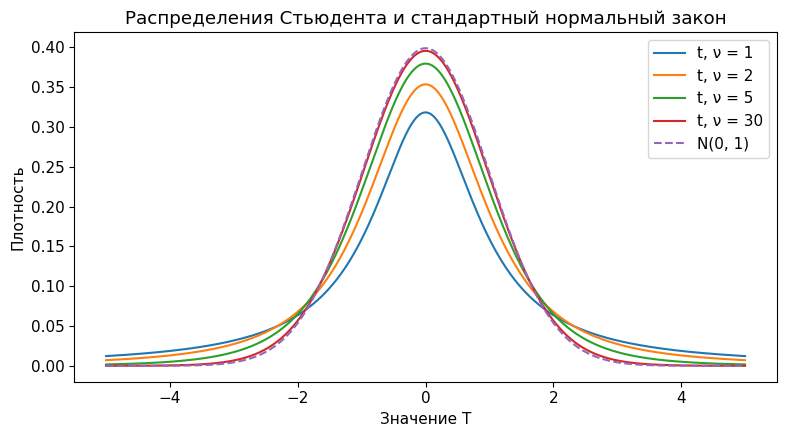

In [39]:
grid_t = np.linspace(-5, 5, 800)
plt.figure()
for degrees in [1, 2, 5, 30]:
    plt.plot(grid_t, stats.t.pdf(grid_t, degrees), label=f't, ν = {degrees}')
plt.plot(grid_t, stats.norm.pdf(grid_t), linestyle='--', label='N(0, 1)')
plt.xlabel('Значение T')
plt.ylabel('Плотность')
plt.title('Распределения Стьюдента и стандартный нормальный закон')
plt.legend()
plt.tight_layout()
plt.show()

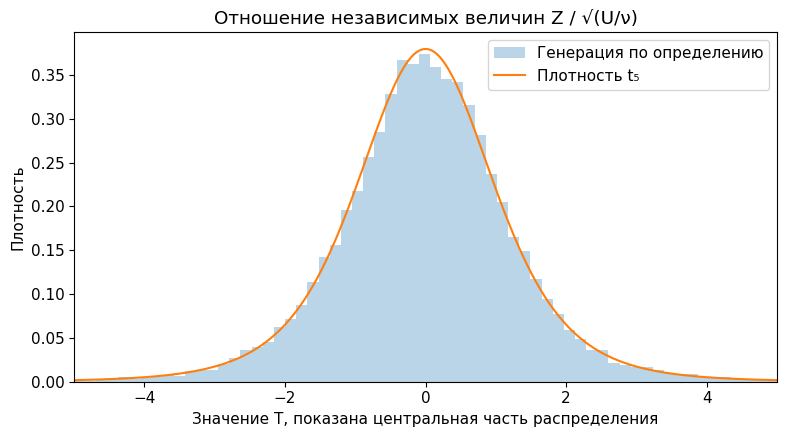

In [40]:
plt.figure()
plt.hist(t_from_definition, bins=180, density=True, alpha=0.3, label='Генерация по определению')
plt.plot(grid_t, stats.t.pdf(grid_t, nu_t), label='Плотность t₅')
plt.xlim(-5, 5)
plt.xlabel('Значение T, показана центральная часть распределения')
plt.ylabel('Плотность')
plt.title('Отношение независимых величин Z / √(U/ν)')
plt.legend()
plt.tight_layout()
plt.show()

### 5.3. Степени свободы в выборочных статистиках

Для независимой нормальной выборки $X_i\sim N(\mu,\sigma^2)$ выполняются соотношения
$$\frac{(n-1)S^2}{\sigma^2}\sim\chi^2_{n-1},\qquad
\frac{\bar X-\mu}{S/\sqrt n}\sim t_{n-1}.$$
Здесь $S^2$ обозначает исправленную выборочную дисперсию. После вычитания среднего остатки удовлетворяют равенству $\sum_i(X_i-\bar X)=0$. Из этой связи следует, что последний остаток определяется по остальным. Число свободно изменяющихся координат уменьшается до $n-1$.

При нормальном законе сумма квадратов нормированных остатков имеет распределение $\chi^2_{n-1}$. Кроме того, $\bar X$ и $S^2$ независимы. Эти свойства дают приведённое распределение отношения Стьюдента. Проверим его форму на повторных выборках.

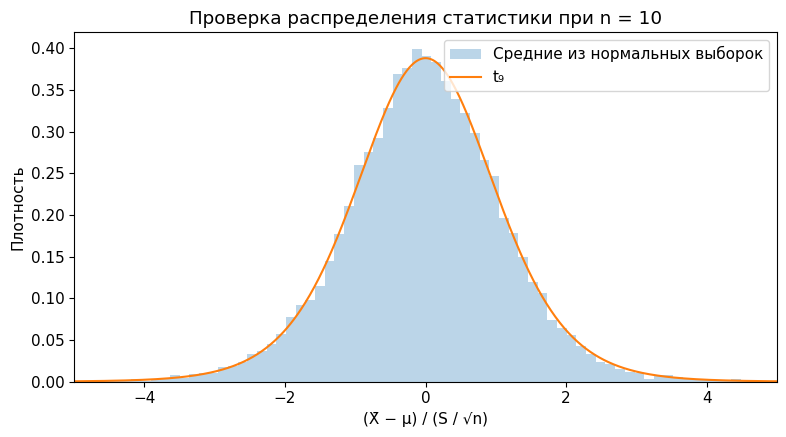

In [41]:
rng_pivot = np.random.default_rng(303)
pivot_n = 10
pivot_samples = rng_pivot.normal(80, 8, size=(20_000, pivot_n))
t_pivot = (pivot_samples.mean(axis=1) - 80) / (pivot_samples.std(axis=1, ddof=1) / np.sqrt(pivot_n))
plt.figure()
plt.hist(t_pivot, bins=100, density=True, alpha=0.3, label='Средние из нормальных выборок')
plt.plot(grid_t, stats.t.pdf(grid_t, pivot_n - 1), label='t₉')
plt.xlim(-5, 5)
plt.xlabel('(X̄ − μ) / (S / √n)')
plt.ylabel('Плотность')
plt.title('Проверка распределения статистики при n = 10')
plt.legend()
plt.tight_layout()
plt.show()

### 5.4. Квантили и критические области

Квантиль уровня $p$ обозначим $q_p=F^{-1}(p)$. В SciPy она вычисляется методом `ppf`. Для рассматриваемых непрерывных распределений интервал
$$[q_{\alpha/2},q_{1-\alpha/2}]$$
содержит значения с суммарной вероятностью $1-\alpha$. В каждом из двух оставшихся хвостов сосредоточена вероятность $\alpha/2$.

При проверке гипотезы заранее задают распределение статистики в предположении, что нулевая гипотеза верна. Для двухсторонней проверки хвостовые области могут быть приняты за критическую область. Если вычисленная статистика попадает в неё, нулевую гипотезу отвергают на выбранном уровне значимости. В дальнейшем будем различать это правило решения и оценку величины наблюдаемого эффекта.

In [42]:
significance = 0.05
nu_critical = 9
t_bounds = stats.t.ppf([significance / 2, 1 - significance / 2], df=nu_critical)
chi_bounds = stats.chi2.ppf([significance / 2, 1 - significance / 2], df=nu_critical)
display(pd.DataFrame({'закон': ['t₉', 'χ²₉'],
                      'нижний квантиль': [t_bounds[0], chi_bounds[0]],
                      'верхний квантиль': [t_bounds[1], chi_bounds[1]]}))
print('Вероятность центральной области t:', np.diff(stats.t.cdf(t_bounds, nu_critical))[0])

,закон,нижний квантиль,верхний квантиль
0,t₉,-2.2622,2.2622
1,χ²₉,2.7004,19.0228


Вероятность центральной области t: 0.9500000000045679


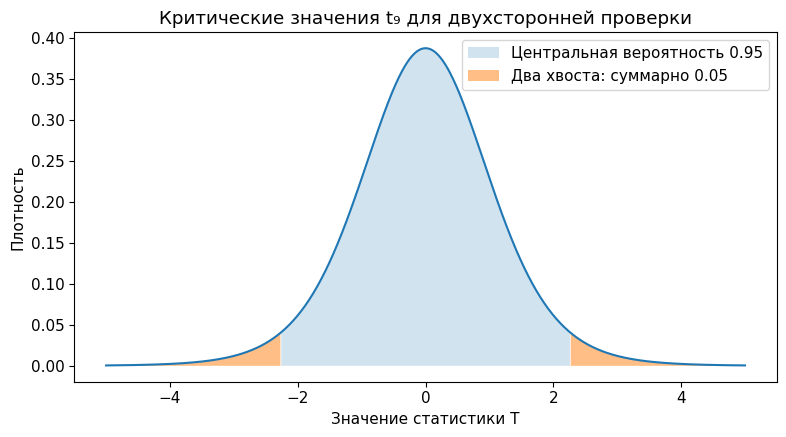

In [43]:
plt.figure()
plt.plot(grid_t, stats.t.pdf(grid_t, nu_critical))
plt.fill_between(grid_t, stats.t.pdf(grid_t, nu_critical),
                 where=(grid_t >= t_bounds[0]) & (grid_t <= t_bounds[1]), alpha=0.2, label='Центральная вероятность 0.95')
plt.fill_between(grid_t, stats.t.pdf(grid_t, nu_critical),
                 where=(grid_t <= t_bounds[0]) | (grid_t >= t_bounds[1]), alpha=0.5, label='Два хвоста: суммарно 0.05')
plt.xlabel('Значение статистики T')
plt.ylabel('Плотность')
plt.title('Критические значения t₉ для двухсторонней проверки')
plt.legend()
plt.tight_layout()
plt.show()

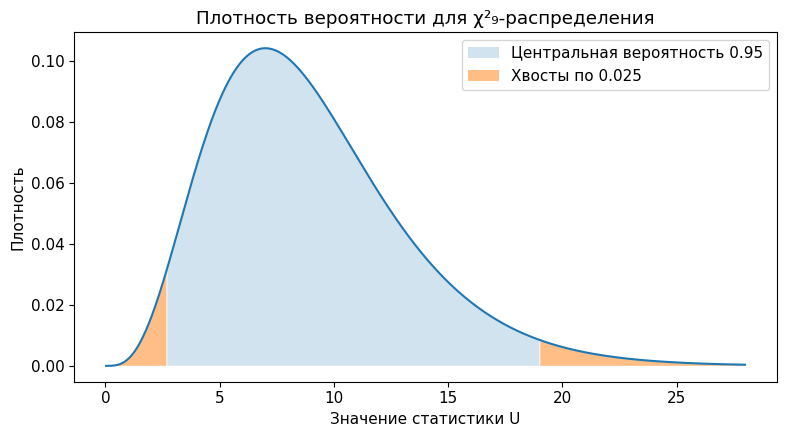

In [44]:
plt.figure()
plt.plot(grid_chi, stats.chi2.pdf(grid_chi, nu_critical))
plt.fill_between(grid_chi, stats.chi2.pdf(grid_chi, nu_critical),
                 where=(grid_chi >= chi_bounds[0]) & (grid_chi <= chi_bounds[1]), alpha=0.2, label='Центральная вероятность 0.95')
plt.fill_between(grid_chi, stats.chi2.pdf(grid_chi, nu_critical),
                 where=(grid_chi <= chi_bounds[0]) | (grid_chi >= chi_bounds[1]), alpha=0.5, label='Хвосты по 0.025')
plt.xlabel('Значение статистики U')
plt.ylabel('Плотность')
plt.title('Плотность вероятности для χ²₉-распределения')
plt.legend()
plt.tight_layout()
plt.show()

### 5.5. Доверительный интервал математического ожидания

Рассмотрим независимую нормальную выборку с неизвестной дисперсией. Для статистики Стьюдента справедливо
$$P\!\left(-t_{1-\alpha/2,n-1}\le\frac{\bar X-\mu}{S/\sqrt n}\le t_{1-\alpha/2,n-1}\right)=1-\alpha.$$
Преобразуем неравенства так, чтобы между границами оказался параметр $\mu$. После подстановки наблюдаемых значений получим интервал
$$\boxed{\ \bar x\pm t_{1-\alpha/2,n-1}\frac{s}{\sqrt n}\ }.$$
Величина $s$ вычисляется с делителем $n-1$. При выполнении предположений этот интервал имеет доверительный уровень $1-\alpha$.

Для других распределений формулу иногда применяют приближённо. Точность такого применения зависит от формы распределения, объёма выборки и существования необходимых моментов. В подразделе 5.8 исследуем её на экспоненциальных данных.

Справка. [NIST — доверительные границы среднего](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm).

In [45]:
n_fit = len(fit_sample)
s_fit = fit_sample.std(ddof=1)
t_critical_fit = stats.t.ppf(0.975, df=n_fit - 1)
mean_margin = t_critical_fit * s_fit / np.sqrt(n_fit)
ci_mean = np.array([fit_sample.mean() - mean_margin, fit_sample.mean() + mean_margin])
print('Среднее:', fit_sample.mean())
print('Стандартное отклонение наблюдений:', s_fit)
print('Оценка стандартной ошибки:', s_fit / np.sqrt(n_fit))
print('95%-й доверительный интервал для μ:', ci_mean)
print('Накрыл известную в опыте μ = 80:', ci_mean[0] <= 80 <= ci_mean[1])

Среднее: 80.0495084297639
Стандартное отклонение наблюдений: 8.928053972626122
Оценка стандартной ошибки: 1.152606811667398
95%-й доверительный интервал для μ: [77.74314753 82.35586933]
Накрыл известную в опыте μ = 80: True


### 5.6. Доверительные интервалы дисперсии и стандартного отклонения

Для той же нормальной модели имеем
$$P\!\left(\chi^2_{\alpha/2,n-1}\le\frac{(n-1)S^2}{\sigma^2}
\le\chi^2_{1-\alpha/2,n-1}\right)=1-\alpha.$$
Выразим из двойного неравенства границы для $\sigma^2$. Поскольку параметр стоит в знаменателе, большая квантиль войдёт в нижнюю границу интервала.
$$\boxed{\ \left[\frac{(n-1)s^2}{\chi^2_{1-\alpha/2,n-1}},
\frac{(n-1)s^2}{\chi^2_{\alpha/2,n-1}}\right]\ }.$$
Для получения интервала стандартного отклонения $\sigma$ извлечём квадратный корень из каждой границы.

Вывод основан на распределении $\chi^2$ для статистики $(n-1)S^2/\sigma^2$ при нормальных наблюдениях. Условие нормальности следует учитывать при применении формулы к данным. Проверку её покрытия для другого закона проведём отдельно.

Справка. [NIST — дисперсия и стандартное отклонение](https://www.itl.nist.gov/div898/handbook/eda/section3/eda358.htm).

In [46]:
chi_critical_fit = stats.chi2.ppf([0.025, 0.975], df=n_fit - 1)
ci_variance = (n_fit - 1) * s_fit**2 / chi_critical_fit[::-1]
ci_std = np.sqrt(ci_variance)
display(pd.DataFrame({
    'параметр': ['μ', 'σ²', 'σ'],
    'нижняя граница': [ci_mean[0], ci_variance[0], ci_std[0]],
    'верхняя граница': [ci_mean[1], ci_variance[1], ci_std[1]],
    'истина в опыте': [80, 64, 8],
    'единицы': ['мм рт. ст.', '(мм рт. ст.)²', 'мм рт. ст.'],
}))

,параметр,нижняя граница,верхняя граница,истина в опыте,единицы
0,μ,77.7431,82.3559,80,мм рт. ст.
1,σ²,57.2704,118.5748,64,(мм рт. ст.)²
2,σ,7.5677,10.8892,8,мм рт. ст.


### 5.7. Проверка покрытия при доверительном уровне 95%

Получим много выборок из одного нормального распределения. В каждом повторении построим интервалы для математического ожидания, дисперсии и стандартного отклонения. Затем подсчитаем долю интервалов, содержащих соответствующий известный параметр. Эту долю называют оценкой покрытия.

Сравним результат с заданным уровнем 0.95. При $B$ повторениях стандартная ошибка доли покрытия приближённо равна $\sqrt{\hat p(1-\hat p)/B}$. Она позволяет оценить случайные колебания результатов самого вычислительного опыта.

In [47]:
rng_coverage = np.random.default_rng(304)
coverage_n, coverage_repeats = 20, 5_000
coverage_samples = rng_coverage.normal(80, 8, (coverage_repeats, coverage_n))
coverage_means = coverage_samples.mean(axis=1)
coverage_std = coverage_samples.std(axis=1, ddof=1)
coverage_half = stats.t.ppf(0.975, coverage_n - 1) * coverage_std / np.sqrt(coverage_n)
mean_low, mean_high = coverage_means - coverage_half, coverage_means + coverage_half
q_cov = stats.chi2.ppf([0.025, 0.975], coverage_n - 1)
var_low = (coverage_n - 1) * coverage_std**2 / q_cov[1]
var_high = (coverage_n - 1) * coverage_std**2 / q_cov[0]
covered_mean = (mean_low <= 80) & (80 <= mean_high)
covered_var = (var_low <= 64) & (64 <= var_high)
covered_std = (np.sqrt(var_low) <= 8) & (8 <= np.sqrt(var_high))

In [48]:
coverages = pd.Series({'μ': covered_mean.mean(), 'σ²': covered_var.mean(), 'σ': covered_std.mean()})
display(pd.DataFrame({'покрытие': coverages,
                      'ошибка Монте-Карло': np.sqrt(coverages * (1 - coverages) / coverage_repeats)}))
assert np.array_equal(covered_var, covered_std)
print('Покрытие для σ и σ² совпадает, поскольку квадратный корень монотонен.')

,покрытие,ошибка Монте-Карло
μ,0.9470,0.0032
σ²,0.9484,0.0031
σ,0.9484,0.0031


Покрытие для σ и σ² совпадает, поскольку квадратный корень монотонен.


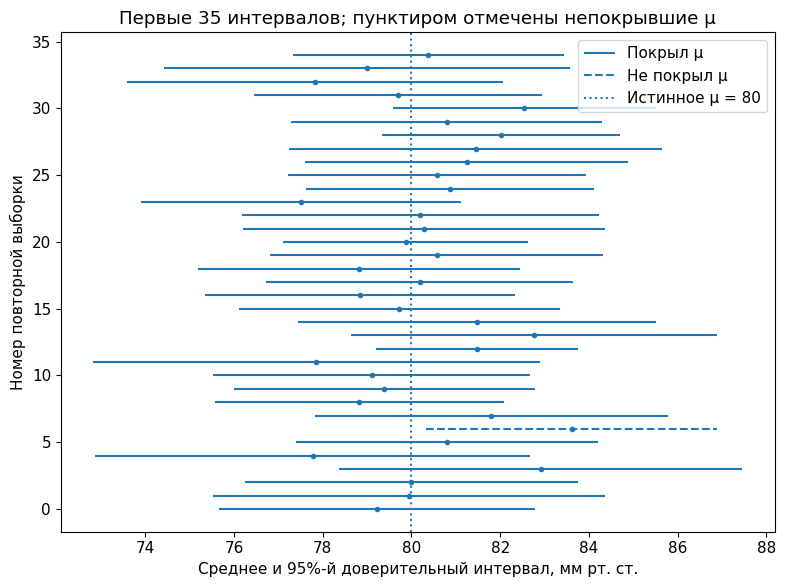

In [49]:
plt.figure(figsize=(8, 6))
for hit, line_style, label in [(True, '-', 'Покрыл μ'), (False, '--', 'Не покрыл μ')]:
    indices = np.flatnonzero(covered_mean[:35] == hit)
    plt.hlines(indices, mean_low[indices], mean_high[indices], linestyles=line_style, label=label)
plt.plot(coverage_means[:35], np.arange(35), linestyle='none', marker='o', markersize=3)
plt.axvline(80, linestyle=':', label='Истинное μ = 80')
plt.xlabel('Среднее и 95%-й доверительный интервал, мм рт. ст.')
plt.ylabel('Номер повторной выборки')
plt.title('Первые 35 интервалов; пунктиром отмечены непокрывшие μ')
plt.legend()
plt.tight_layout()
plt.show()

### 5.8. Покрытие интервалов на экспоненциальных данных

Теперь получим наблюдения из экспоненциального распределения. Применим к ним формулы интервалов, выведенные для нормальной выборки, и измерим покрытие при разных объёмах $n$. Сопоставим результаты для математического ожидания и дисперсии.

В каждом случае проведём несколько тысяч повторений. Начальное состояние генератора зафиксируем до получения результатов. По таблице рассмотрим, как меняется расхождение между заданным и наблюдаемым уровнями покрытия.

In [50]:
rng_skew = np.random.default_rng(305)
coverage_rows = []
for n_skew in [10, 30, 100, 500]:
    skew_samples = rng_skew.exponential(5, (4_000, n_skew))
    skew_mean = skew_samples.mean(axis=1)
    skew_var = skew_samples.var(axis=1, ddof=1)
    skew_margin = stats.t.ppf(0.975, n_skew - 1) * np.sqrt(skew_var / n_skew)
    q_skew = stats.chi2.ppf([0.025, 0.975], n_skew - 1)
    low_var = (n_skew - 1) * skew_var / q_skew[1]
    high_var = (n_skew - 1) * skew_var / q_skew[0]
    coverage_rows.append([n_skew, np.mean(np.abs(skew_mean - 5) <= skew_margin),
                          np.mean((low_var <= 25) & (25 <= high_var))])
skew_coverage_table = pd.DataFrame(coverage_rows, columns=['n', 'покрытие μ: t', 'покрытие σ²: χ²'])
display(skew_coverage_table)

,n,покрытие μ: t,покрытие σ²: χ²
0,10,0.9048,0.7718
1,30,0.9270,0.7250
2,100,0.9380,0.6925
3,500,0.9510,0.6763


### ★ 5.9. Точный интервал среднего экспоненциального закона

Пусть $X_i$ независимы и имеют распределение $\operatorname{Exp}(\lambda)$ с нулевым сдвигом. Для их суммы выполняется
$$2\lambda\sum_iX_i\sim\chi^2_{2n}.$$
Выражая из соответствующих квантильных неравенств параметр $\mu=1/\lambda$, получаем точный доверительный интервал
$$\left[\frac{2\sum_i x_i}{\chi^2_{1-\alpha/2,2n}},\quad
\frac{2\sum_i x_i}{\chi^2_{\alpha/2,2n}}\right].$$
В основе построения лежит распределение суммы наблюдений. Экспоненциальный закон является частным случаем гамма-распределения с параметром формы 1. Сумма независимых гамма-величин с общим масштабом также имеет гамма-распределение. Это свойство даёт используемый здесь закон χ² с $2n$ степенями свободы.

In [51]:
rng_exact_exp = np.random.default_rng(306)
exact_n = 10
exact_exp_samples = rng_exact_exp.exponential(5, (5_000, exact_n))
exact_sums = exact_exp_samples.sum(axis=1)
q_exact = stats.chi2.ppf([0.025, 0.975], 2 * exact_n)
exact_low = 2 * exact_sums / q_exact[1]
exact_high = 2 * exact_sums / q_exact[0]
exact_coverage = np.mean((exact_low <= 5) & (5 <= exact_high))
print('Покрытие точного интервала μ для Exp:', exact_coverage)

Покрытие точного интервала μ для Exp: 0.948


### 5.10. Интервалы для параметра и для наблюдения

При известных параметрах распределения центральный интервал $[F^{-1}(0.025),F^{-1}(0.975)]$ содержит отдельное наблюдение с вероятностью 0.95. Доверительный интервал среднего строится по выборке для оценки неизвестного $\mu$.

Можно также поставить задачу о границах для одного нового наблюдения. При независимых нормальных наблюдениях с неизвестными параметрами соответствующий предиктивный интервал имеет вид
$$\bar x\pm t_{0.975,n-1}s\sqrt{1+1/n}.$$
Сопоставьте его формулу с интервалом для $\mu$. Вычислим оба интервала на одной выборке.

Метод `stats.norm.interval(0.95, loc=..., scale=...)` возвращает центральный интервал заданного нормального закона. Для истолкования результата нужно указать, распределение какой величины описывают переданные параметры.

In [52]:
central_known = stats.norm.ppf([0.025, 0.975], loc=80, scale=8)
prediction_half = t_critical_fit * s_fit * np.sqrt(1 + 1 / n_fit)
prediction_interval = fit_sample.mean() + np.array([-1, 1]) * prediction_half
display(pd.DataFrame([central_known, ci_mean, prediction_interval],
    index=['Наблюдение: истинные параметры известны', 'Доверительный интервал μ',
           'Новое наблюдение: параметры оценены'], columns=['нижняя граница', 'верхняя граница']))

,нижняя граница,верхняя граница
Наблюдение: истинные параметры известны,64.3203,95.6797
Доверительный интервал μ,77.7431,82.3559
Новое наблюдение: параметры оценены,62.0363,98.0628


<a id="bayes"></a>
## 6. Условные вероятности и теорема Байеса

### 6.1. Вероятности по двум столбцам

Обозначим через $A$ событие «курит», а через $B$ событие «метка равна 1». При $P(B)>0$ условная вероятность определяется равенством
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)}.$$
Для её оценки по таблице сначала выберем объекты, для которых выполнено условие $B$. Затем найдём среди них долю объектов с признаком $A$. Расчёт возможен, если выбранная группа содержит хотя бы один объект.

Таблица сопряжённости показывает число наблюдений для каждой пары значений двух столбцов. Составим её, затем разделим частоты на суммы по строкам и по столбцам. Для каждого результата укажем, какая группа принята за основание расчёта долей.

In [53]:
counts_smoke_y = pd.crosstab(df['курение'], df['гипертония']).reindex(index=[0, 1], columns=[0, 1], fill_value=0)
print('Числа объектов: строки — курение, столбцы — метка')
display(counts_smoke_y)
print('P(курение | метка): сумма каждого столбца = 1')
display(counts_smoke_y.div(counts_smoke_y.sum(axis=0), axis=1))
print('P(метка | курение): сумма каждой строки = 1')
display(counts_smoke_y.div(counts_smoke_y.sum(axis=1), axis=0))

Числа объектов: строки — курение, столбцы — метка


гипертония,0,1
курение,,
0,6,2
1,0,2


P(курение | метка): сумма каждого столбца = 1


гипертония,0,1
курение,,
0,1.0,0.5
1,0.0,0.5


P(метка | курение): сумма каждой строки = 1


гипертония,0,1
курение,,
0,0.75,0.25
1,0.00,1.00


In [54]:
a_event = df['курение'].eq(1)
b_event = df['гипертония'].eq(1)
p_a_emp = a_event.mean()
p_b_emp = b_event.mean()
p_ab_emp = (a_event & b_event).mean()
print('P(A):', p_a_emp, 'P(B):', p_b_emp, 'P(A∩B):', p_ab_emp)
print('P(A|B):', p_ab_emp / p_b_emp)
print('P(B|A):', p_ab_emp / p_a_emp)

P(A): 0.2 P(B): 0.4 P(A∩B): 0.2
P(A|B): 0.5
P(B|A): 1.0


### 6.2. Теорема Байеса для событий

Вероятность совместного выполнения событий можно записать двумя способами $P(A\cap B)=P(A\mid B)P(B)=P(B\mid A)P(A)$. При $P(A)>0$ отсюда следует
$$P(B\mid A)=\frac{P(A\mid B)P(B)}{P(A)}.$$
Если события $B_0,\ldots,B_{k-1}$ образуют разбиение пространства исходов, формула принимает вид
$$P(B_c\mid A)=\frac{P(A\mid B_c)P(B_c)}{\sum_{r=0}^{k-1}P(A\mid B_r)P(B_r)}.$$
События такого разбиения взаимно исключают друг друга и охватывают все возможные исходы. В задаче классификации они соответствуют классам. Вероятность класса до учёта признаков данного объекта называют априорной. Вероятность с учётом наблюдаемых признаков называют апостериорной.

Применим формулу к частотам маленькой таблицы. При обсуждении результата укажем, сколько наблюдений участвовало в каждой условной доле.

### 6.3. Известные условные распределения

Перейдём от частот таблицы к модели с заданными параметрами. Пусть для класса $Y$, индикатора курения $S$ и давления $D$ выполнены условия
$$P(Y=1)=0.35,\quad P(S=1\mid Y=0)=0.15,\quad P(S=1\mid Y=1)=0.30,$$
$$D\mid Y=0\sim N(80,8^2),\qquad D\mid Y=1\sim N(92,10^2).$$
Для события $A=\{85\le D\le90\}$ вычислим вероятность попадания в интервал в каждом классе. Затем применим теорему Байеса, чтобы получить вероятность класса при выполнении события $A$.

In [55]:
known_priors = np.array([0.65, 0.35])
known_smoking = np.array([0.15, 0.30])
known_means = np.array([80.0, 92.0])
known_stds = np.array([8.0, 10.0])
p_interval_given_class = stats.norm.cdf(90, known_means, known_stds) - stats.norm.cdf(85, known_means, known_stds)
interval_weights = known_priors * p_interval_given_class
interval_posterior = interval_weights / interval_weights.sum()
display(pd.DataFrame({'P(Y=c)': known_priors, 'P(85≤D≤90 | Y=c)': p_interval_given_class,
                      'P(Y=c | 85≤D≤90)': interval_posterior}, index=[0, 1]))

,P(Y=c),P(85≤D≤90 | Y=c),P(Y=c | 85≤D≤90)
0,0.65,0.1603,0.6248
1,0.35,0.1788,0.3752


### 6.4. Теорема Байеса для непрерывного признака

Пусть в каждом классе давление имеет плотность $f_c$, а вероятность класса равна $\pi_c$. При наблюдении $D=d$ вероятность класса выражается формулой
$$P(Y=c\mid D=d)=\frac{\pi_c f_c(d)}{\sum_r\pi_r f_r(d)},\qquad \pi_c=P(Y=c).$$
Знаменатель должен быть положительным. При непрерывных плотностях эту формулу можно получить, применяя теорему Байеса к всё более узким интервалам вокруг $d$ и переходя к пределу.

Сумма $f_D(d)=\sum_c\pi_c f_c(d)$ задаёт общую плотность давления. Такое распределение называют смесью распределений классов. Построим условные плотности и рассмотрим, как их значения участвуют в расчёте вероятности класса.

In [56]:
observed_pressure = 88.0
pressure_densities = normal_pdf(observed_pressure, known_means, known_stds)
pressure_weights = known_priors * pressure_densities
pressure_posterior = pressure_weights / pressure_weights.sum()
display(pd.DataFrame({'f(d | Y=c)': pressure_densities, 'π_c f(d | Y=c)': pressure_weights,
                      'P(Y=c | D=d)': pressure_posterior}, index=[0, 1]))

,f(d | Y=c),π_c f(d | Y=c),P(Y=c | D=d)
0,0.0302,0.0197,0.604
1,0.0368,0.0129,0.396


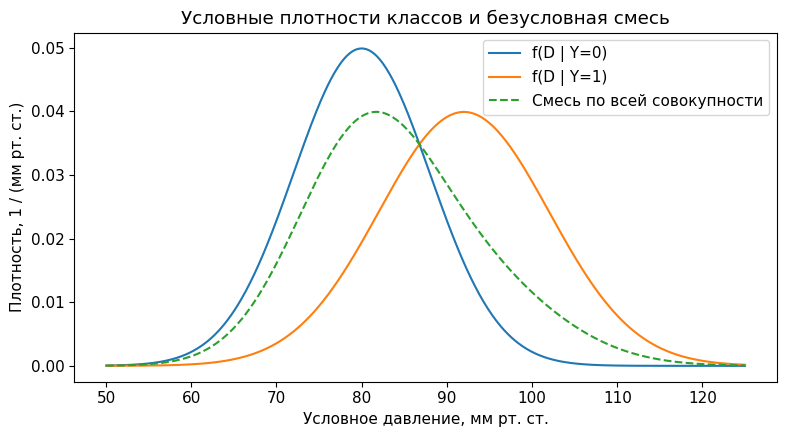

In [57]:
grid_conditional = np.linspace(50, 125, 600)
plt.figure()
for c in [0, 1]:
    plt.plot(grid_conditional, normal_pdf(grid_conditional, known_means[c], known_stds[c]), label=f'f(D | Y={c})')
mixture_density = sum(known_priors[c] * normal_pdf(grid_conditional, known_means[c], known_stds[c]) for c in [0, 1])
plt.plot(grid_conditional, mixture_density, linestyle='--', label='Смесь по всей совокупности')
plt.xlabel('Условное давление, мм рт. ст.')
plt.ylabel('Плотность, 1 / (мм рт. ст.)')
plt.title('Условные плотности классов и безусловная смесь')
plt.legend()
plt.tight_layout()
plt.show()

<a id="naive-bayes"></a>
## 7. Наивный байесовский классификатор

### 7.1. Предположение модели и оцениваемые параметры

Для объекта $\mathbf x=(x_1,\ldots,x_m)$ требуется вычислить вероятности классов $P(Y=c\mid\mathbf X=\mathbf x)$. Примем условную независимость признаков при заданном классе. При этом предположении совместное распределение признаков представляется произведением
$$p(\mathbf x\mid Y=c)=\prod_{j=1}^m p_j(x_j\mid Y=c).$$
Здесь $p_j$ означает функцию вероятностей дискретного признака или плотность непрерывного. Теорема Байеса даёт
$$P(Y=c\mid\mathbf x)=\frac{\pi_c\prod_jp_j(x_j\mid c)}{\sum_r\pi_r\prod_jp_j(x_j\mid r)}.$$
В качестве прогноза выберем класс с наибольшей вероятностью. При верной модели и одинаковой цене ошибок это правило минимизирует вероятность неверной классификации.

Для обучения найдём доли классов и оценим распределения признаков отдельно в каждом классе. Далее будем применять частотные оценки и метод максимального правдоподобия. Полученные параметры подставляются в формулу прогноза как фиксированные числа. Неопределённость их оценивания в этом расчёте отдельно не моделируется.

Справка. [руководство scikit-learn по наивному Байесу](https://scikit-learn.org/stable/modules/naive_bayes.html).

### 7.2. Категориальная модель и таблицы вероятностей

Сначала заменим возраст и давление номерами заранее заданных интервалов. Такое представление позволит записать все вероятности в небольших таблицах. Границы выбраны для учебного примера.

Для признака $j$ с $R_j$ категориями используем оценку
$$\hat p_j(r\mid c)=\frac{N_{cjr}+a}{N_c+aR_j},\qquad a>0.$$
Здесь $N_{cjr}$ — число объектов класса $c$ с категорией $r$, а $N_c$ — общее число объектов этого класса. Добавка $a$ называется коэффициентом сглаживания. При $a=1$ используется сглаживание Лапласа. Доли классов оценим отдельно по формуле $\hat\pi_c=N_c/n$.

Множество допустимых категорий задают заранее или определяют по обучающей выборке. Для значений, которые могут появиться позднее, можно предусмотреть дополнительную категорию «другое». Рассмотрим, как добавка $a$ влияет на значения таблиц.

In [58]:
cat_small = pd.DataFrame({
    'интервал_возраста': np.digitize(age, [45, 60]),
    'интервал_давления': np.digitize(dbp, [85, 95]),
    'курение': smoking,
})
category_sizes = {'интервал_возраста': 3, 'интервал_давления': 3, 'курение': 2}
print('Код 0 — ниже первой границы, 1 — между границами, 2 — выше второй.')
display(cat_small.assign(метка=y))

Код 0 — ниже первой границы, 1 — между границами, 2 — выше второй.


,интервал_возраста,интервал_давления,курение,метка
0,0,0,0,0
1,0,0,0,0
2,0,0,0,0
3,0,0,0,0
4,1,1,1,1
5,1,0,0,0
6,1,1,0,1
7,2,1,0,0
8,2,2,1,1
9,2,1,0,1


In [59]:
smoothing = 1.0
class_counts_small = pd.Series(y).value_counts().sort_index()
class_priors_small = class_counts_small / len(y)
category_tables = {}
for column, n_categories in category_sizes.items():
    counts = pd.crosstab(cat_small[column], y).reindex(index=range(n_categories), columns=[0, 1], fill_value=0)
    category_tables[column] = (counts + smoothing).div(class_counts_small + smoothing * n_categories, axis=1)
    print(column, '— строки: категории; столбцы: классы')
    display(category_tables[column])
    np.testing.assert_allclose(category_tables[column].sum(axis=0), 1)

интервал_возраста — строки: категории; столбцы: классы


col_0,0,1
интервал_возраста,,
0,0.5556,0.1429
1,0.2222,0.4286
2,0.2222,0.4286


интервал_давления — строки: категории; столбцы: классы


col_0,0,1
интервал_давления,,
0,0.6667,0.1429
1,0.2222,0.5714
2,0.1111,0.2857


курение — строки: категории; столбцы: классы


col_0,0,1
курение,,
0,0.875,0.5
1,0.125,0.5


### 7.3. Расчёт одного прогноза по таблицам

Рассмотрим объект с кодами 1 для возраста, давления и курения. Для каждого класса выберем из таблиц три соответствующие вероятности. Умножим их на вероятность класса и получим его вес. Разделив каждый вес на сумму весов всех классов, найдём вероятности прогноза.

Сопоставим вычисление по отдельным множителям с результатом готовой функции.

In [60]:
new_categories = {'интервал_возраста': 1, 'интервал_давления': 1, 'курение': 1}
cat_factors = pd.DataFrame({column: category_tables[column].loc[value]
                            for column, value in new_categories.items()})
cat_factors.insert(0, 'априорная', class_priors_small)
cat_weights = cat_factors.prod(axis=1)
cat_posterior = cat_weights / cat_weights.sum()
display(cat_factors.assign(вес=cat_weights, вероятность=cat_posterior))
print('Прогноз:', cat_posterior.idxmax())

,априорная,интервал_возраста,интервал_давления,курение,вес,вероятность
col_0,,,,,,
0,0.6,0.2222,0.2222,0.125,0.0037,0.0703
1,0.4,0.4286,0.5714,0.500,0.0490,0.9297


Прогноз: 1


In [61]:
from sklearn.naive_bayes import CategoricalNB, BernoulliNB, GaussianNB
categorical_reference = CategoricalNB(alpha=smoothing, min_categories=[3, 3, 2])
categorical_reference.fit(cat_small.to_numpy(), y)
reference_cat_posterior = categorical_reference.predict_proba([list(new_categories.values())])[0]
np.testing.assert_allclose(cat_posterior.to_numpy(), reference_cat_posterior)
print('Ручной расчёт совпал с CategoricalNB:', reference_cat_posterior)

Ручной расчёт совпал с CategoricalNB: [0.07030129 0.92969871]


### 7.4. Бернуллиевская модель

Для бинарных признаков $x_j\in\{0,1\}$ условное распределение и оценки его параметров записываются в виде
$$p(\mathbf x\mid c)=\prod_j\theta_{cj}^{x_j}(1-\theta_{cj})^{1-x_j},\qquad
\hat\theta_{cj}=\frac{N_{cj}^{(1)}+a}{N_c+2a}.$$
Величина $\theta_{cj}$ задаёт вероятность единицы для признака $j$ в классе $c$. Подставьте в один множитель сначала $x_j=1$, затем $x_j=0$ и проследите, какие вероятности входят в произведение.

Получим три бинарных столбца по фиксированным учебным порогам. Рассчитаем прогноз по формуле и сравним его с результатом `BernoulliNB`.

Справка. [BernoulliNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.BernoulliNB.html).

In [62]:
binary_small = np.column_stack([age >= 55, dbp >= 88, smoking]).astype(int)
bernoulli_parameters = np.vstack([
    (binary_small[y == c].sum(axis=0) + 1) / ((y == c).sum() + 2) for c in [0, 1]
])
display(pd.DataFrame(bernoulli_parameters, index=['класс 0', 'класс 1'],
                      columns=['P(возраст≥55)', 'P(давление≥88)', 'P(курение)']))
new_binary = np.array([1, 1, 0])
bern_likelihood = np.prod(bernoulli_parameters**new_binary * (1-bernoulli_parameters)**(1-new_binary), axis=1)
bern_weights = class_priors_small.to_numpy() * bern_likelihood
bern_posterior = bern_weights / bern_weights.sum()
print('Вероятности классов:', bern_posterior)

,P(возраст≥55),P(давление≥88),P(курение)
класс 0,0.2500,0.1250,0.125
класс 1,0.6667,0.8333,0.500


Вероятности классов: [0.12865895 0.87134105]


In [63]:
bernoulli_reference = BernoulliNB(alpha=1.0, binarize=None).fit(binary_small, y)
np.testing.assert_allclose(bern_posterior, bernoulli_reference.predict_proba(new_binary[None, :])[0])
print('Ручной расчёт совпал с BernoulliNB.')

Ручной расчёт совпал с BernoulliNB.


### 7.5. Гауссовская модель и параметры плотности

Для каждого непрерывного признака примем нормальное распределение внутри класса. Его параметры оценим по соответствующей группе наблюдений.
$$\hat\mu_{cj}=\frac1{N_c}\sum_{i:y_i=c}x_{ij},\qquad
\hat\sigma^2_{cj}=\frac1{N_c}\sum_{i:y_i=c}(x_{ij}-\hat\mu_{cj})^2.$$
Таким образом, для каждого признака и класса сохраняются два числа, задающие плотность. В вычислениях к дисперсии добавляют малую положительную величину, чтобы формула плотности оставалась определённой при очень малом разбросе или совпадении наблюдений.

Начнём с одного признака — давления. По маленькой таблице найдём параметры каждого класса и построим плотности. К проверке качества на новых объектах перейдём после рассмотрения большей выборки.

Справка. [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html).

,число,среднее,дисперсия ML
0,6,79.3167,18.4914
1,4,92.5250,12.0219


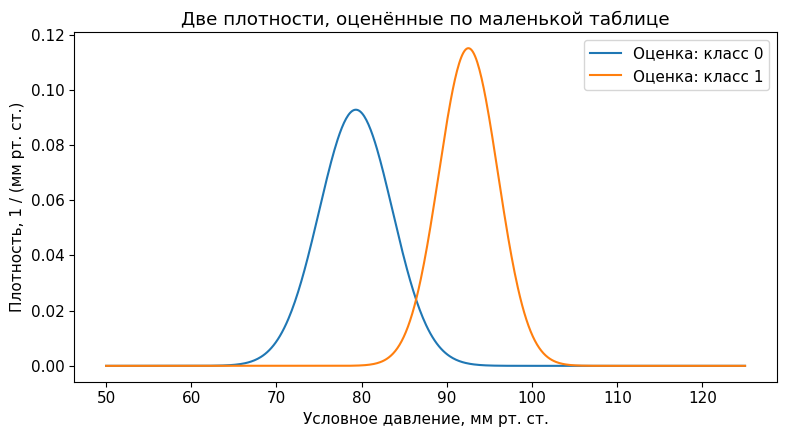

In [64]:
pressure_parameters_small = pd.DataFrame({
    'число': [(y == c).sum() for c in [0, 1]],
    'среднее': [dbp[y == c].mean() for c in [0, 1]],
    'дисперсия ML': [dbp[y == c].var(ddof=0) for c in [0, 1]],
}, index=[0, 1])
display(pressure_parameters_small)
plt.figure()
for c in [0, 1]:
    pars = pressure_parameters_small.loc[c]
    plt.plot(grid_conditional, normal_pdf(grid_conditional, pars['среднее'], np.sqrt(pars['дисперсия ML'])), label=f'Оценка: класс {c}')
plt.xlabel('Условное давление, мм рт. ст.')
plt.ylabel('Плотность, 1 / (мм рт. ст.)')
plt.title('Две плотности, оценённые по маленькой таблице')
plt.legend()
plt.tight_layout()
plt.show()

### 7.6. Вычисление логарифмических весов

При перемножении большого числа малых множителей результат может оказаться ниже машинной точности. Для расчёта введём логарифм веса класса
$$\ell_c=\log\pi_c+\sum_j\log p_j(x_j\mid c).$$
Для нормального закона логарифм плотности имеет вид
$$\log f(x;\mu,v)=-\tfrac12\log(2\pi v)-\frac{(x-\mu)^2}{2v}.$$
Чтобы восстановить вероятности из логарифмических весов, сначала вычтем их общий максимум.
$$P(Y=c\mid\mathbf x)=\frac{e^{\ell_c-M}}{\sum_r e^{\ell_r-M}},\qquad M=\max_r\ell_r.$$
В числителе и знаменателе возникает один и тот же множитель $e^{-M}$, который сокращается. При этом показатели экспонент становятся неположительными, а наибольшая экспонента равна единице. Функция `logsumexp` использует сходный приём для вычисления логарифма суммы экспонент.

In [65]:
def normal_logpdf(values, mean, variance):
    if np.any(np.asarray(variance) <= 0):
        raise ValueError('Дисперсия должна быть положительной.')
    return -0.5 * (np.log(2 * np.pi * variance) + (np.asarray(values) - mean)**2 / variance)

def probabilities_from_scores(scores):
    scores = np.atleast_2d(np.asarray(scores, dtype=float))
    if not np.isfinite(scores).all():
        raise ValueError('Нужны конечные логарифмические веса.')
    shifted = scores - scores.max(axis=1, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=1, keepdims=True)

print('Прямое произведение:', np.prod(np.full(1_000, 0.01)))
print('Логарифм произведения:', np.log(0.01) * 1_000)

Прямое произведение: 0.0
Логарифм произведения: -4605.170185988091


In [66]:
demo_scores = np.array([[-1001.0, -1000.0], [-20.0, -23.0]])
demo_probabilities = probabilities_from_scores(demo_scores)
reference_probabilities = np.exp(demo_scores - logsumexp(demo_scores, axis=1, keepdims=True))
np.testing.assert_allclose(demo_probabilities, reference_probabilities)
display(pd.DataFrame(demo_probabilities, columns=['P(класс 0)', 'P(класс 1)']))

,P(класс 0),P(класс 1)
0,0.2689,0.7311
1,0.9526,0.0474


### 7.7. Большая синтетическая выборка

Сгенерируем 6 000 объектов. Для каждого объекта сначала выберем класс, затем независимо получим три признака по условным распределениям этого класса. Такой порядок служит способом получения данных из совместного закона.

Законы давления и курения заданы в разделе 6. Для исходного, ещё не округлённого возраста $A^*$ примем
$$\log A^*\mid Y=0\sim N(\log42,0.22^2),\qquad
\log A^*\mid Y=1\sim N(\log56,0.20^2).$$
Наблюдаемый возраст получим округлением до ближайшего целого. Значения ниже единицы заменим единицей. Это задаёт нижнюю границу допустимых возрастов в учебной модели. При выбранных параметрах такие замены крайне редки.

Общая вероятность курения равна $0.65\cdot0.15+0.35\cdot0.30=0.2025$. Для описания возраста и давления по всей таблице нужно учитывать доли обоих классов. Рассмотрим полученную выборку и её характеристики по группам.

In [67]:
def make_patients(n, seed):
    rng = np.random.default_rng(seed)
    labels = rng.binomial(1, 0.35, size=n)
    age_latent = rng.lognormal(np.log(np.where(labels == 0, 42, 56)),
                              np.where(labels == 0, 0.22, 0.20))
    pressure = rng.normal(np.where(labels == 0, 80, 92), np.where(labels == 0, 8, 10))
    smoke = rng.binomial(1, np.where(labels == 0, 0.15, 0.30))
    return pd.DataFrame({'возраст': np.maximum(1, np.rint(age_latent)).astype(int),
                         'диастолическое_давление': pressure, 'курение': smoke,
                         'гипертония': labels})

large_df = make_patients(6_000, seed=401)
display(large_df.head())
print('Наблюдаемая доля курящих:', large_df['курение'].mean())

,возраст,диастолическое_давление,курение,гипертония
0,59,87.5685,1,1
1,33,69.3913,0,0
2,35,88.0721,0,0
3,47,93.0736,0,1
4,64,97.6749,0,1


Наблюдаемая доля курящих: 0.209


### 7.8. Разделение выборки до обучения

Оставим 25% объектов для проверки. Доли классов, средние, дисперсии и вероятности категорий будем оценивать по остальным объектам, образующим обучающую часть. По этому же правилу в реальных задачах вычисляют медианы для заполнения пропусков и границы интервалов для преобразования признаков.

Аргумент `stratify` позволяет сохранить близкие доли классов в обеих частях. В нашем генераторе объекты независимы. Если же таблица содержит повторные измерения одних и тех же людей, разбиение следует выполнять по людям, сохраняя связанные строки в одной части.

Справка. [предотвращение утечки данных](https://scikit-learn.org/stable/common_pitfalls.html).

In [68]:
from sklearn.model_selection import train_test_split
train_df, test_df = train_test_split(large_df, test_size=0.25, random_state=402,
                                    stratify=large_df['гипертония'])
assert set(train_df.index).isdisjoint(test_df.index)
display(pd.DataFrame({'число объектов': [len(train_df), len(test_df)],
                      'доля класса 1': [train_df['гипертония'].mean(), test_df['гипертония'].mean()]},
                     index=['обучение', 'проверка']))

,число объектов,доля класса 1
обучение,4500,0.3504
проверка,1500,0.3500


### 7.9. Смешанная модель с параметрами в таблице

Для возраста возьмём логнормальную плотность как непрерывное приближение округлённых значений. Для давления используем нормальную плотность, для курения — закон Бернулли. Среднее и дисперсию логарифма возраста оценим по его записанным значениям. Эти оценки будут приближёнными с учётом проведённого округления.

Соберём параметры в таблицу. Для дисперсий зададим малую положительную нижнюю границу. Вероятности курения вычислим со сглаживанием $a=1$, а доли классов найдём по обычным частотам.

In [69]:
def fit_mixed(table, smoothing=1.0):
    if smoothing <= 0 or (table['возраст'] <= 0).any():
        raise ValueError('Нужны a > 0 и положительные возраста.')
    rows = []
    for c, group in table.groupby('гипертония', sort=True):
        log_age = np.log(group['возраст'].to_numpy())
        pressure = group['диастолическое_давление'].to_numpy()
        rows.append([c, len(group), len(group) / len(table), log_age.mean(),
                     max(log_age.var(ddof=0), 1e-12), pressure.mean(),
                     max(pressure.var(ddof=0), 1e-12),
                     (group['курение'].sum() + smoothing) / (len(group) + 2*smoothing)])
    return pd.DataFrame(rows, columns=['класс', 'n', 'prior', 'age_log_mean', 'age_log_var',
                                       'dbp_mean', 'dbp_var', 'smoke_p']).set_index('класс')

mixed_parameters = fit_mixed(train_df)
display(mixed_parameters)

,n,prior,age_log_mean,age_log_var,dbp_mean,dbp_var,smoke_p
класс,,,,,,,
0,2923,0.6496,3.7453,0.0509,79.7962,64.7997,0.1535
1,1577,0.3504,4.0322,0.0398,91.9687,95.7879,0.3192


Параметры `age_log_mean` и `age_log_var` описывают логарифм возраста. При переходе к плотности самого возраста появляется множитель $1/a$. Поэтому
$$\log f_A(a\mid c)=\log f_{\log A}(\log a\mid c)-\log a.$$
Для одного объекта возраст $a$ одинаков во всех сравниваемых классах. Проследите, как член $-\log a$ участвует в нормировке весов. В функции сохраним полное выражение логарифма плотности.

In [70]:
def mixed_log_scores(table, parameters):
    ages = table['возраст'].to_numpy(dtype=float)
    pressure = table['диастолическое_давление'].to_numpy(dtype=float)
    smoke = table['курение'].to_numpy(dtype=float)
    if np.any(ages <= 0) or not np.isin(smoke, [0, 1]).all():
        raise ValueError('Возраст должен быть положительным, курение — 0 или 1.')
    scores = []
    for _, par in parameters.iterrows():
        age_term = normal_logpdf(np.log(ages), par['age_log_mean'], par['age_log_var']) - np.log(ages)
        dbp_term = normal_logpdf(pressure, par['dbp_mean'], par['dbp_var'])
        smoke_term = smoke*np.log(par['smoke_p']) + (1-smoke)*np.log1p(-par['smoke_p'])
        scores.append(np.log(par['prior']) + age_term + dbp_term + smoke_term)
    return np.column_stack(scores)

### 7.10. Слагаемые одного прогноза

Рассмотрим объект с возрастом 58 лет, давлением 90 и индикатором курения 0. Для каждого класса выведем логарифм априорной вероятности и слагаемые от отдельных признаков. Затем вычислим итоговые вероятности.

Сравнивать вклад одного признака между классами будем при одинаковых единицах измерения. Найдите разности соответствующих слагаемых и сопоставьте их с итоговым прогнозом.

In [71]:
new_patient = pd.DataFrame({'возраст': [58], 'диастолическое_давление': [90.0], 'курение': [0]})
contributions = pd.DataFrame(index=mixed_parameters.index)
contributions['log prior'] = np.log(mixed_parameters['prior'])
contributions['возраст'] = normal_logpdf(np.log(58), mixed_parameters['age_log_mean'], mixed_parameters['age_log_var']) - np.log(58)
contributions['давление'] = normal_logpdf(90, mixed_parameters['dbp_mean'], mixed_parameters['dbp_var'])
contributions['не курит'] = np.log1p(-mixed_parameters['smoke_p'])
contributions['сумма'] = contributions.sum(axis=1)
contributions['вероятность'] = probabilities_from_scores(contributions['сумма'].to_numpy())[0]
display(contributions)
np.testing.assert_allclose(contributions['сумма'], mixed_log_scores(new_patient, mixed_parameters)[0])

,log prior,возраст,давление,не курит,сумма,вероятность
класс,,,,,,
0,-0.4315,-4.4660,-3.8080,-0.1667,-8.8721,0.3012
1,-1.0486,-3.3772,-3.2202,-0.3845,-8.0305,0.6988


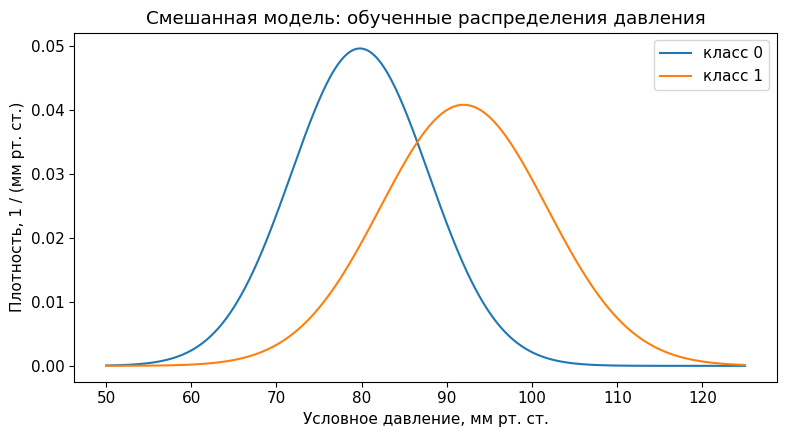

In [72]:
plt.figure()
for c, par in mixed_parameters.iterrows():
    grid_mixed_pressure = np.linspace(50, 125, 500)
    plt.plot(grid_mixed_pressure, normal_pdf(grid_mixed_pressure, par['dbp_mean'], np.sqrt(par['dbp_var'])), label=f'класс {c}')
plt.xlabel('Условное давление, мм рт. ст.')
plt.ylabel('Плотность, 1 / (мм рт. ст.)')
plt.title('Смешанная модель: обученные распределения давления')
plt.legend()
plt.tight_layout()
plt.show()

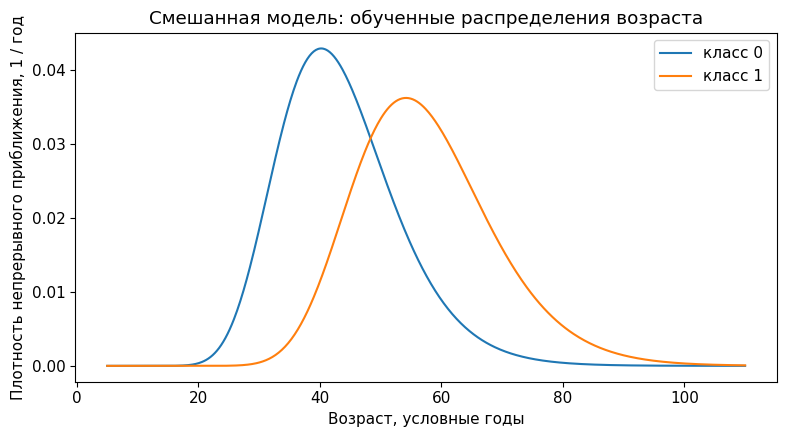

In [73]:
plt.figure()
for c, par in mixed_parameters.iterrows():
    plt.plot(grid_age, lognormal_pdf(grid_age, par['age_log_mean'], np.sqrt(par['age_log_var'])), label=f'класс {c}')
plt.xlabel('Возраст, условные годы')
plt.ylabel('Плотность непрерывного приближения, 1 / год')
plt.title('Смешанная модель: обученные распределения возраста')
plt.legend()
plt.tight_layout()
plt.show()

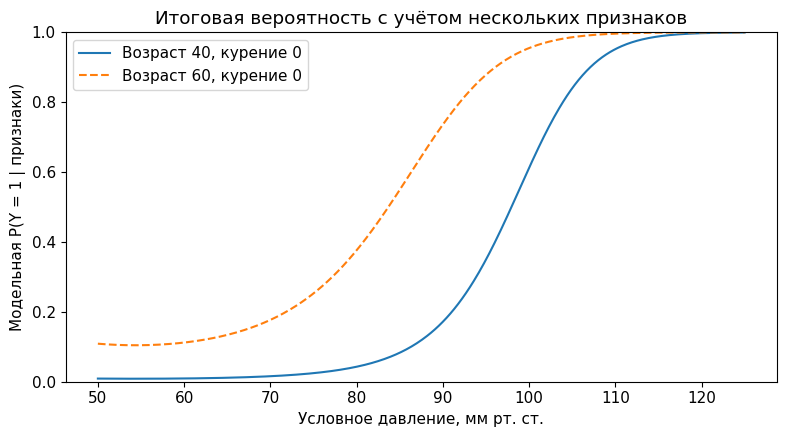

In [74]:
plt.figure()
for fixed_age, line_style in [(40, '-'), (60, '--')]:
    pressure_grid_frame = pd.DataFrame({'возраст': fixed_age,
        'диастолическое_давление': grid_mixed_pressure, 'курение': 0})
    curve_prob = probabilities_from_scores(mixed_log_scores(pressure_grid_frame, mixed_parameters))[:, 1]
    plt.plot(grid_mixed_pressure, curve_prob, linestyle=line_style, label=f'Возраст {fixed_age}, курение 0')
plt.xlabel('Условное давление, мм рт. ст.')
plt.ylabel('Модельная P(Y = 1 | признаки)')
plt.ylim(0, 1)
plt.title('Итоговая вероятность с учётом нескольких признаков')
plt.legend()
plt.tight_layout()
plt.show()

### ★ 7.11. Вероятность округлённого возраста

В принятой модели целому возрасту $a\ge2$ соответствует интервал исходных значений от $a-0.5$ до $a+0.5$. Поэтому
$$P(A=a\mid c)=F_c(a+0.5)-F_c(a-0.5).$$
Для $a=1$ нижняя граница равна 0, поскольку все значения, округлённые ниже единицы, заменялись единицей. Полученную вероятность можно использовать совместно с плотностью давления и вероятностью индикатора курения. Для всех классов при этом сохраняется один способ описания наблюдений.

В следующем расчёте учтём интервалы округления, оставив прежние приближённые оценки параметров. Чтобы оценить параметры методом максимального правдоподобия именно для округлённой модели, пришлось бы максимизировать сумму логарифмов этих интервальных вероятностей.

In [75]:
def rounded_age_logpmf(ages, mean_log, variance_log):
    ages = np.asarray(ages, dtype=float)
    if np.any(ages < 1) or np.any(ages != np.floor(ages)):
        raise ValueError('Нужны положительные целые возраста.')
    lower = np.where(ages == 1, 0, ages - 0.5)
    law = stats.lognorm(s=np.sqrt(variance_log), scale=np.exp(mean_log))
    left_mass = law.cdf(ages + 0.5) - law.cdf(lower)
    right_mass = law.sf(lower) - law.sf(ages + 0.5)
    mass = np.where(ages > np.exp(mean_log), right_mass, left_mass)
    return np.log(np.maximum(mass, np.finfo(float).tiny))

В правом хвосте вычислим вероятность интервала как разность значений `sf`. Это позволяет избежать вычитания двух значений `cdf`, близких к единице. В последней строке функции предусмотрена нижняя машинная граница на случай численного обнуления. В рассматриваемом диапазоне возрастов полученные вероятности остаются выше этой границы.

In [76]:
def mixed_rounded_log_scores(table, parameters):
    scores = mixed_log_scores(table, parameters).copy()
    ages = table['возраст'].to_numpy(dtype=float)
    for j, (_, par) in enumerate(parameters.iterrows()):
        continuous_term = normal_logpdf(np.log(ages), par['age_log_mean'], par['age_log_var']) - np.log(ages)
        scores[:, j] += rounded_age_logpmf(ages, par['age_log_mean'], par['age_log_var']) - continuous_term
    return scores

p_continuous = probabilities_from_scores(mixed_log_scores(new_patient, mixed_parameters))[0]
p_rounded = probabilities_from_scores(mixed_rounded_log_scores(new_patient, mixed_parameters))[0]
display(pd.DataFrame({'плотность как приближение': p_continuous,
                      'вероятность интервала округления': p_rounded}, index=[0, 1]))

,плотность как приближение,вероятность интервала округления
0,0.3012,0.3013
1,0.6988,0.6987


### 7.12. Проверка на новых объектах

Вычислим показатели на обучающей и отложенной частях выборки. Результаты на отложенных объектах используем для оценки применения модели к новым данным. Для класса 1 найдём precision, recall и F1. Качество вероятностных прогнозов оценим также с помощью log loss и Brier score.

В бинарной задаче $\operatorname{Brier}=n^{-1}\sum_i(p_i-y_i)^2$. Логарифмическая потеря равна $-n^{-1}\sum_i\log P(Y=y_i\mid\mathbf x_i)$. Обе величины уменьшаются при улучшении прогноза в соответствующем смысле. Рассмотрим их вместе с показателями классификации. Сопоставлению вероятностей с наблюдаемыми долями будет посвящён отдельный опыт.

In [77]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, log_loss, brier_score_loss, confusion_matrix)

def binary_metrics(labels, probabilities):
    predictions = np.argmax(probabilities, axis=1)
    return {'accuracy': accuracy_score(labels, predictions),
            'balanced accuracy': balanced_accuracy_score(labels, predictions),
            'precision, класс 1': precision_score(labels, predictions, zero_division=0),
            'recall, класс 1': recall_score(labels, predictions, zero_division=0),
            'F1, класс 1': f1_score(labels, predictions, zero_division=0),
            'log loss': log_loss(labels, probabilities, labels=[0, 1]),
            'Brier': brier_score_loss(labels, probabilities[:, 1])}

mixed_train_prob = probabilities_from_scores(mixed_log_scores(train_df, mixed_parameters))
mixed_test_prob = probabilities_from_scores(mixed_log_scores(test_df, mixed_parameters))

In [78]:
mixed_test_rounded = probabilities_from_scores(mixed_rounded_log_scores(test_df, mixed_parameters))
mixed_metrics = pd.DataFrame({
    'обучение': binary_metrics(train_df['гипертония'], mixed_train_prob),
    'проверка': binary_metrics(test_df['гипертония'], mixed_test_prob),
    'округление': binary_metrics(test_df['гипертония'], mixed_test_rounded),
})
display(mixed_metrics)
np.testing.assert_allclose(mixed_test_prob.sum(axis=1), 1)
assert np.isfinite(mixed_test_prob).all()

,обучение,проверка,округление
accuracy,0.8480,0.8440,0.8440
balanced accuracy,0.8245,0.8207,0.8207
"precision, класс 1",0.8060,0.7975,0.7975
"recall, класс 1",0.7457,0.7429,0.7429
"F1, класс 1",0.7747,0.7692,0.7692
log loss,0.3375,0.3426,0.3426
Brier,0.1069,0.1089,0.1089


### ★ 7.13. Задача XOR и условная независимость

Рассмотрим четыре равновероятные комбинации двух бинарных признаков. Метку зададим правилом $Y=X_1\oplus X_2$, то есть значением операции «исключающее ИЛИ».

Выпишем значения признаков отдельно для каждого класса. Найдём их условные вероятности и рассчитаем прогноз наивного Байеса. Сопоставьте полученный результат с исходной таблицей меток. Затем рассмотрите связь между признаками во всей таблице и внутри каждого класса.

In [79]:
xor_X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
xor_y = np.array([0, 1, 1, 0])
xor_model = BernoulliNB(alpha=1, binarize=None).fit(xor_X, xor_y)
xor_probability = xor_model.predict_proba(xor_X)
display(pd.DataFrame({'x₁': xor_X[:, 0], 'x₂': xor_X[:, 1], 'истина': xor_y,
                      'P(Y=1)': xor_probability[:, 1], 'прогноз': xor_model.predict(xor_X)}))
np.testing.assert_allclose(xor_probability, 0.5)

,x₁,x₂,истина,P(Y=1),прогноз
0,0,0,0,0.5,0
1,0,1,1,0.5,0
2,1,0,1,0.5,0
3,1,1,0,0.5,0


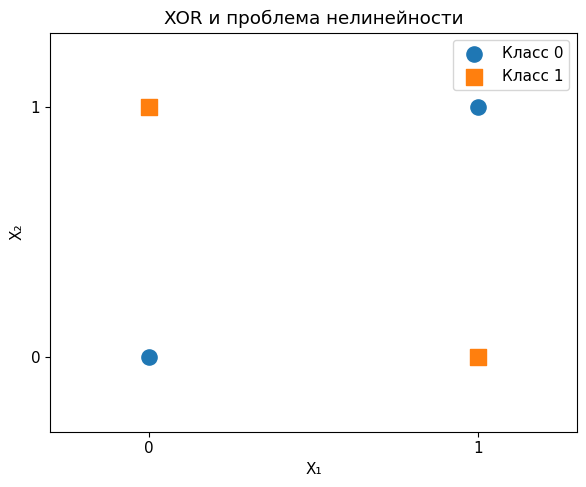

In [80]:
plt.figure(figsize=(6, 5))
for c, marker in [(0, 'o'), (1, 's')]:
    points = xor_X[xor_y == c]
    plt.scatter(points[:, 0], points[:, 1], marker=marker, s=120, label=f'Класс {c}')
plt.xticks([0, 1]); plt.yticks([0, 1])
plt.xlim(-0.3, 1.3); plt.ylim(-0.3, 1.3)
plt.xlabel('X₁'); plt.ylabel('X₂')
plt.title('XOR и проблема нелинейности')
plt.legend()
plt.tight_layout()
plt.show()

<a id="real-data"></a>
## 8. Реальный набор Wisconsin Diagnostic Breast Cancer

В наборе содержатся 569 объектов и 30 числовых признаков, рассчитанных по оцифрованным изображениям клеточных ядер. Требуется различать доброкачественные и злокачественные образования. Применим к этой таблице изученные способы построения классификатора.

Набор входит в scikit-learn и доступен без отдельного скачивания. В исходной кодировке метка 0 соответствует `malignant`, а метка 1 — `benign`. Перекодируем метки так, чтобы в наших расчётах класс 1 обозначал злокачественное образование. С этой кодировкой далее будут связаны precision и recall.

Авторы набора W. H. Wolberg, W. N. Street и O. L. Mangasarian. Описание и происхождение данных приведены на [странице UCI](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic), DOI 10.24432/C5DW2B. Репозиторий указывает лицензию CC BY 4.0. Способ загрузки описан в документации [load_breast_cancer](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).

In [81]:
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer(as_frame=True)
real_X = cancer.data.copy()
real_y = (cancer.target == 0).astype(int).rename('злокачественное_образование')
print('Форма признаков:', real_X.shape)
print('Исходные названия классов:', cancer.target_names)
print('Пропущенные значения:', int(real_X.isna().sum().sum()))
display(real_X.iloc[:5, :5].join(real_y))
assert real_X.shape == (569, 30) and real_X.notna().all().all()

Форма признаков: (569, 30)
Исходные названия классов: ['malignant' 'benign']
Пропущенные значения: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,злокачественное_образование
0,17.99,10.38,122.80,1001.0,0.1184,1
1,20.57,17.77,132.90,1326.0,0.0847,1
2,19.69,21.25,130.00,1203.0,0.1096,1
3,11.42,20.38,77.58,386.1,0.1425,1
4,20.29,14.34,135.10,1297.0,0.1003,1


### 8.1. Условия сравнения

Основной разбор проведём по трём признакам `mean radius`, `mean texture` и `mean smoothness`. Их небольшой набор позволит представить оценки параметров в обозримой таблице. Для сравнения заранее зададим гауссовскую модель на всех 30 признаках, а также два преобразования выбранных трёх столбцов. Первое использует медианы для бинаризации, второе — квантили уровней 1/3 и 2/3 для выделения трёх категорий.

Выделим общую проверочную часть. Все медианы, квантили и параметры распределений вычислим по обучающей части. Полученные результаты будут относиться к заранее заданным вариантам. Для выбора настроек потребовалась бы дополнительная валидационная выборка или перекрёстная проверка внутри обучения.

In [82]:
real_columns = ['mean radius', 'mean texture', 'mean smoothness']
real_train_X, real_test_X, real_train_y, real_test_y = train_test_split(
    real_X, real_y, test_size=0.25, random_state=501, stratify=real_y)
real_train_3 = real_train_X[real_columns].to_numpy()
real_test_3 = real_test_X[real_columns].to_numpy()
real_train_labels = real_train_y.to_numpy()
real_test_labels = real_test_y.to_numpy()
assert set(real_train_X.index).isdisjoint(real_test_X.index)
print('Обучение / проверка:', len(real_train_X), len(real_test_X))
display(real_train_X[real_columns].describe())

Обучение / проверка: 426 143


,mean radius,mean texture,mean smoothness
count,426.0000,426.0000,426.0000
mean,14.0095,19.1733,0.0967
std,3.3658,4.2984,0.0142
min,6.9810,10.3800,0.0625
25%,11.6950,16.0400,0.0860
50%,13.2750,18.7850,0.0969
75%,15.6475,21.5675,0.1054
max,27.2200,39.2800,0.1634


### 8.2. Обучение гауссовского наивного Байеса средствами NumPy

Запишем две функции. Первая вычисляет параметры модели и возвращает словарь массивов. Вторая находит логарифмические веса классов. Массив `classes` задаёт порядок столбцов вероятностей. После поиска столбца с наибольшим значением его номер переводится в метку с помощью этого массива.

Добавку к дисперсии вычислим по правилу `GaussianNB`. Для этого умножим `var_smoothing` на наибольшую дисперсию признака, рассчитанную по всей обучающей части. Полученное число прибавим к каждой внутриклассовой дисперсии. Величина добавки зависит от масштаба признаков и используется для устойчивости вычислений. Если все столбцы постоянны, требуется отдельно обработать этот вырожденный случай.

In [83]:
def fit_gaussian_nb(values, labels, var_smoothing=1e-9):
    values, labels = np.asarray(values, dtype=float), np.asarray(labels)
    
    if values.ndim != 2 or labels.shape != (len(values),) or not np.isfinite(values).all():
        raise ValueError('Нужны конечная матрица X и согласованный вектор y.')
    
    classes, counts = np.unique(labels, return_counts=True)
    means = np.vstack([values[labels == c].mean(axis=0) for c in classes])
    variances = np.vstack([values[labels == c].var(axis=0, ddof=0) for c in classes])
    epsilon = var_smoothing * values.var(axis=0, ddof=0).max()
    variances = variances + epsilon
    
    if var_smoothing < 0 or np.any(variances <= 0):
        raise ValueError('Нужна положительная дисперсия после регуляризации.')
    
    return {'classes': classes, 'prior': counts / len(labels), 'mean': means,
            'variance': variances, 'epsilon': epsilon}

In [84]:
def gaussian_log_scores(values, parameters):
    values = np.asarray(values, dtype=float)
    scores = []
    for c in range(len(parameters['classes'])):
        terms = normal_logpdf(values, parameters['mean'][c], parameters['variance'][c])
        scores.append(np.log(parameters['prior'][c]) + terms.sum(axis=1))
    return np.column_stack(scores)

real_gaussian_3 = fit_gaussian_nb(real_train_3, real_train_labels)
real_prob_3 = probabilities_from_scores(gaussian_log_scores(real_test_3, real_gaussian_3))
real_pred_3 = real_gaussian_3['classes'][real_prob_3.argmax(axis=1)]

In [85]:
parameter_table_real = pd.DataFrame({
    'класс': np.repeat(real_gaussian_3['classes'], len(real_columns)),
    'признак': real_columns * len(real_gaussian_3['classes']),
    'среднее': real_gaussian_3['mean'].ravel(),
    'дисперсия + добавка': real_gaussian_3['variance'].ravel(),
})
display(parameter_table_real)
real_reference_3 = GaussianNB(var_smoothing=1e-9).fit(real_train_3, real_train_labels)
np.testing.assert_allclose(real_prob_3, real_reference_3.predict_proba(real_test_3), rtol=1e-9, atol=1e-12)
print('Все вероятности ручной реализации совпали с GaussianNB.')

,класс,признак,среднее,дисперсия + добавка
0,0,mean radius,12.1426,3.2121
1,0,mean texture,17.7641,15.2830
2,0,mean smoothness,0.0929,0.0002
3,1,mean radius,17.1444,9.2062
4,1,mean texture,21.5398,14.7875
5,1,mean smoothness,0.1032,0.0002


Все вероятности ручной реализации совпали с GaussianNB.


### 8.3. Подобранные плотности на реальных данных

Построим гистограммы признака `mean radius` для обучающих объектов каждого класса. На тех же осях изобразим нормальные плотности с оценёнными параметрами. Сохраним исходную шкалу набора.

Сопоставьте положение и форму гистограмм с кривыми. Затем рассмотрим таблицы корреляций внутри классов, чтобы перейти от распределения одного признака к связям между признаками.

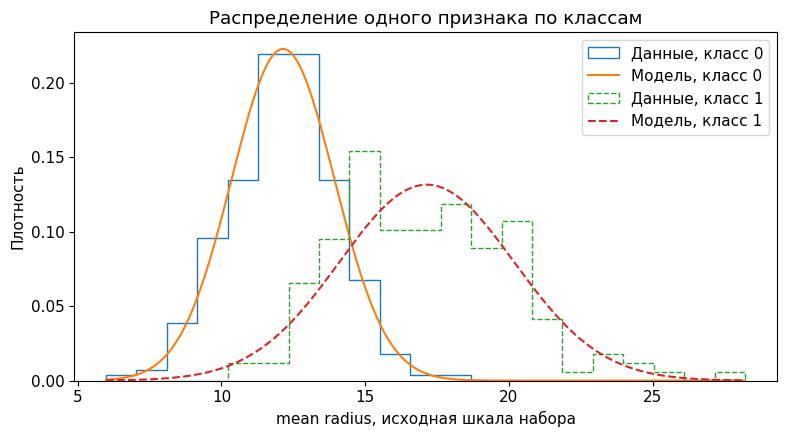

In [86]:
radius_grid = np.linspace(real_train_3[:, 0].min() - 1, real_train_3[:, 0].max() + 1, 500)
radius_bins = np.linspace(radius_grid.min(), radius_grid.max(), 22)
plt.figure()
for c, line_style in [(0, '-'), (1, '--')]:
    subset = real_train_3[real_train_labels == c, 0]
    plt.hist(subset, 
             bins=radius_bins, 
             density=True, 
             histtype='step', 
             linestyle=line_style, 
             label=f'Данные, класс {c}'
            )
    plt.plot(radius_grid, 
             normal_pdf(radius_grid, real_gaussian_3['mean'][c, 0],
             np.sqrt(real_gaussian_3['variance'][c, 0])), 
             linestyle=line_style, 
             label=f'Модель, класс {c}'
            )
plt.xlabel('mean radius, исходная шкала набора')
plt.ylabel('Плотность')
plt.title('Распределение одного признака по классам')
plt.legend()
plt.tight_layout()
plt.show()

In [87]:
correlation_columns = ['mean radius', 'mean perimeter', 'mean area']
for c in [0, 1]:
    print('Корреляции на обучении при фиксированном классе', c)
    display(real_train_X.loc[real_train_y == c, correlation_columns].corr())

Корреляции на обучении при фиксированном классе 0


,mean radius,mean perimeter,mean area
mean radius,1.0000,0.9966,0.9941
mean perimeter,0.9966,1.0000,0.9902
mean area,0.9941,0.9902,1.0000


Корреляции на обучении при фиксированном классе 1


,mean radius,mean perimeter,mean area
mean radius,1.0000,0.9953,0.9939
mean perimeter,0.9953,1.0000,0.9902
mean area,0.9939,0.9902,1.0000


### 8.4. Три признака и все тридцать

Повторим расчёт для всех признаков. В каждом классе оценим среднее и дисперсию каждого столбца, затем включим соответствующие слагаемые в логарифмический вес. Сравним ручной расчёт с `GaussianNB`.

Полученные прогнозы сохраним для общей таблицы результатов. По ней позднее сопоставим варианты с тремя и тридцатью признаками.

In [88]:
real_gaussian_all = fit_gaussian_nb(real_train_X.to_numpy(), real_train_labels)
real_prob_all = probabilities_from_scores(gaussian_log_scores(real_test_X.to_numpy(), real_gaussian_all))
real_reference_all = GaussianNB(var_smoothing=1e-9).fit(real_train_X, real_train_y)
np.testing.assert_allclose(real_prob_all, real_reference_all.predict_proba(real_test_X), rtol=1e-8, atol=1e-11)
print('Совпадение с GaussianNB проверено и на 30 признаках.')

Совпадение с GaussianNB проверено и на 30 признаках.


### 8.5. Бернуллиевская модель на реальных признаках

Для применения `BernoulliNB` представим каждый из трёх признаков индикатором превышения медианы. Медианы найдём по обучающей части. Те же значения используем при преобразовании проверочных объектов.

Для матрицы бинарных наблюдений $B$ логарифмические веса всех классов можно вычислить одной матричной записью
$$B\log\Theta^\mathsf T+(1-B)\log(1-\Theta)^\mathsf T+\log\boldsymbol\pi.$$
Матрица $\Theta$ содержит вероятности единицы. Её строки соответствуют классам, а столбцы — признакам. Оператор `@` выполняет матричное умножение. Проследите, как в этой записи суммируются слагаемые для единиц и нулей.

In [89]:
train_medians = np.median(real_train_3, axis=0)
real_binary_train = (real_train_3 > train_medians).astype(int)
real_binary_test = (real_test_3 > train_medians).astype(int)
real_bern_theta = np.vstack([(real_binary_train[real_train_labels == c].sum(axis=0) + 1) /
                            ((real_train_labels == c).sum() + 2) for c in [0, 1]])
real_binary_scores = (real_binary_test @ np.log(real_bern_theta).T +
                     (1-real_binary_test) @ np.log1p(-real_bern_theta).T +
                     np.log(real_gaussian_3['prior']))
real_prob_binary = probabilities_from_scores(real_binary_scores)
real_bern_reference = BernoulliNB(alpha=1, binarize=None).fit(real_binary_train, real_train_labels)
np.testing.assert_allclose(real_prob_binary, real_bern_reference.predict_proba(real_binary_test), atol=1e-12)

### 8.6. Категориальная модель на тех же данных

Разобьём каждый из трёх признаков на интервалы по квантилям уровней 1/3 и 2/3 обучающей выборки. Интервалы получат коды 0, 1 и 2. Функция `np.digitize` определит код каждого наблюдения. Крайние интервалы охватывают также значения за пределами диапазона обучающих данных.

Для таких кодов применяется категориальная модель `CategoricalNB`. Вероятность оценивается отдельно для каждого допустимого кода. Для сравнения, в мультиномиальной модели `MultinomialNB` входными данными служат счётчики событий, например количества употреблений слов в документе.

In [90]:
tertile_edges = np.quantile(real_train_3, [1/3, 2/3], axis=0).T
real_cat_train = np.column_stack([np.digitize(real_train_3[:, j], tertile_edges[j]) for j in range(3)])
real_cat_test = np.column_stack([np.digitize(real_test_3[:, j], tertile_edges[j]) for j in range(3)])
real_cat_tables = []
for j in range(3):
    table_j = np.vstack([(np.bincount(real_cat_train[real_train_labels == c, j], minlength=3) + 1) /
                         ((real_train_labels == c).sum() + 3) for c in [0, 1]])
    real_cat_tables.append(table_j)
print('Границы тертилей: строки — признаки, столбцы — две границы')
display(pd.DataFrame(tertile_edges, index=real_columns, columns=['q(1/3)', 'q(2/3)']))

Границы тертилей: строки — признаки, столбцы — две границы


,q(1/3),q(2/3)
mean radius,12.3000,14.6967
mean texture,17.1067,20.5333
mean smoothness,0.0893,0.1024


In [91]:
real_cat_scores = np.tile(np.log(real_gaussian_3['prior']), (len(real_cat_test), 1))
for j, table_j in enumerate(real_cat_tables):
    real_cat_scores += np.log(table_j[:, real_cat_test[:, j]].T)
real_prob_categorical = probabilities_from_scores(real_cat_scores)
real_cat_reference = CategoricalNB(alpha=1, min_categories=3).fit(real_cat_train, real_train_labels)
np.testing.assert_allclose(real_prob_categorical, real_cat_reference.predict_proba(real_cat_test), atol=1e-12)
print('Категориальные вероятности совпали с CategoricalNB.')

Категориальные вероятности совпали с CategoricalNB.


### 8.7. Сопоставление на общей проверочной части

Добавим простой исходный вариант, который для каждого объекта выдаёт доли классов обучающей выборки. Сопоставим его с моделями, использующими признаки.

В одной таблице вычислим показатели всех заранее выбранных вариантов на общей проверочной части. Выводы будут относиться к этому набору данных и данному разбиению. Сохранение независимости проверки требует, чтобы выбор признаков, порогов и других настроек проводился по обучающим и валидационным данным.

In [92]:
prior_only_probability = np.tile(real_gaussian_3['prior'], (len(real_test_labels), 1))
real_probabilities = {
    'Только доли классов': prior_only_probability,
    'Gaussian 3 признака': real_prob_3,
    'Gaussian 30 признаков': real_prob_all,
    'Bernoulli 3 признака': real_prob_binary,
    'Categorical 3 признака': real_prob_categorical,
}
real_metrics = pd.DataFrame({name: binary_metrics(real_test_labels, probability)
                             for name, probability in real_probabilities.items()}).T
display(real_metrics)

,accuracy,balanced accuracy,"precision, класс 1","recall, класс 1","F1, класс 1",log loss,Brier
Только доли классов,0.6294,0.5000,0.0000,0.0000,0.0000,0.6593,0.2333
Gaussian 3 признака,0.9231,0.9117,0.9200,0.8679,0.8932,0.1927,0.0572
Gaussian 30 признаков,0.9510,0.9378,0.9792,0.8868,0.9307,0.3497,0.0442
Bernoulli 3 признака,0.8601,0.8734,0.7538,0.9245,0.8305,0.3288,0.1023
Categorical 3 признака,0.8811,0.8784,0.8214,0.8679,0.8440,0.2800,0.0837


### 8.8. Матрица ошибок

В строках матрицы укажем истинные классы, в столбцах — предсказанные. Каждая ячейка покажет число объектов с соответствующей парой меток. При нашей кодировке объект класса 1, предсказанный как 0, относится к ложным отрицаниям.

Найдите в матрице верные прогнозы и ошибки обоих видов. Рассмотрение здесь ограничено учебной оценкой классификации на данном наборе.

In [93]:
real_pred_all = real_prob_all.argmax(axis=1)
real_confusion = confusion_matrix(real_test_labels, real_pred_all, labels=[0, 1])
display(pd.DataFrame(real_confusion, index=['истина 0', 'истина 1'], columns=['прогноз 0', 'прогноз 1']))

,прогноз 0,прогноз 1
истина 0,89,1
истина 1,6,47


### 8.9. Сопоставление вероятностей с наблюдаемыми долями

Для модели с 30 признаками разобьём проверочные прогнозы на группы с близкими вероятностями. В каждой группе найдём среднюю предсказанную вероятность и долю объектов класса 1. Совпадению этих величин на графике соответствует диагональ. Такое сопоставление используется при изучении калибровки вероятностей.

Рядом с долями укажем число объектов в группе. По нему можно судить, насколько ограничен объём наблюдений для сравнения. Для обучения дополнительного преобразования вероятностей понадобились бы отдельные данные или перекрёстная проверка внутри обучения. Здесь ограничимся рассмотрением уже полученных прогнозов.

Справка. [калибровка вероятностей в scikit-learn](https://scikit-learn.org/stable/modules/calibration.html).

,число,прогноз,наблюдаемая_доля
0,24,8.8192e-16,0.0000
1,24,8.7973e-14,0.0000
2,24,4.6005e-10,0.0417
3,23,1.3903e-02,0.2174
4,48,9.9647e-01,0.9792


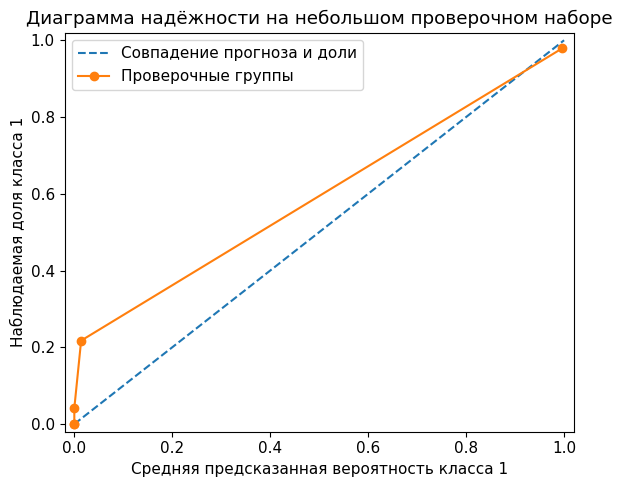

In [94]:
calibration_rows = pd.DataFrame({'p': real_prob_all[:, 1], 'y': real_test_labels})
calibration_rows['группа'] = pd.qcut(calibration_rows['p'], q=6, duplicates='drop')
calibration_table = calibration_rows.groupby('группа', observed=True).agg(
    число=('y', 'size'), прогноз=('p', 'mean'), наблюдаемая_доля=('y', 'mean'))
display(calibration_table.reset_index(drop=True))
plt.figure(figsize=(6, 5))
plt.plot([0, 1], [0, 1], linestyle='--', label='Совпадение прогноза и доли')
plt.plot(calibration_table['прогноз'], calibration_table['наблюдаемая_доля'], marker='o', label='Проверочные группы')
plt.xlabel('Средняя предсказанная вероятность класса 1')
plt.ylabel('Наблюдаемая доля класса 1')
plt.title('Диаграмма надёжности на небольшом проверочном наборе')
plt.xlim(-0.02, 1.02); plt.ylim(-0.02, 1.02)
plt.legend()
plt.tight_layout()
plt.show()

### ★ 8.10. Дублирование признака

Пусть классы равновероятны, а бинарный признак имеет условные вероятности $P(X=1\mid Y=0)=0.2$ и $P(X=1\mid Y=1)=0.8$. Рассмотрим объект со значением $X=1$.

Сначала рассчитайте вероятность класса по одному столбцу. Затем добавьте его точную копию и примените формулу наивного Байеса как для двух признаков. Сопоставьте результаты и обратитесь к предположению об условной независимости. Обсудите, какие сведения об объекте стали доступны после копирования.

<a id="finish"></a>
## 9. Итоги и самостоятельная работа

В практикуме рассмотрен путь от таблицы наблюдений к вероятностному классификатору. Вычисление характеристик столбца привело к оцениванию параметров распределения. Затем те же оценки были получены отдельно по классам и использованы в прогнозе.

Для самостоятельного опыта выберите одно условие, которое предстоит изменить. Сформулируйте, какой результат вы предполагаете получить, и укажите способ его проверки. При обсуждении опыта рассмотрите объём выборки, выбор семейства распределений и связи между признаками внутри классов.

**Перед расчётом.** Уточните смысл строк, признаков и меток. Выделите данные для проверки. Запишите предположения о распределениях и способ обработки измерений. После вычислений проверьте нормировку вероятностей и сопоставьте прогнозы с отложенными наблюдениями. Вывод сформулируйте в пределах проведённого опыта.

<a id="sources"></a>
## Источники и документация

**Операции с данными.** [numpy.mean](https://numpy.org/doc/stable/reference/generated/numpy.mean.html), [var](https://numpy.org/doc/stable/reference/generated/numpy.var.html), [std](https://numpy.org/doc/stable/reference/generated/numpy.std.html), [quantile](https://numpy.org/doc/stable/reference/generated/numpy.quantile.html), [Generator](https://numpy.org/doc/stable/reference/random/generator.html). [pandas.DataFrame](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html), [groupby](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.groupby.html), [crosstab](https://pandas.pydata.org/docs/reference/api/pandas.crosstab.html).

**Распределения SciPy.** [Бернулли](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bernoulli.html), [биномиальное](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html), [Пуассона](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.poisson.html), [равномерное](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.uniform.html), [нормальное](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html), [логнормальное](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.lognorm.html), [экспоненциальное](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.expon.html), [Стьюдента](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.t.html), [χ²](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chi2.html), [гамма](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.gamma.html), [logsumexp](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.logsumexp.html).

**Статистические интервалы.** NIST/SEMATECH, *e-Handbook of Statistical Methods*. [интервал среднего](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm), [дисперсия и стандартное отклонение](https://www.itl.nist.gov/div898/handbook/eda/section3/eda358.htm), [закон Стьюдента](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3664.htm), [закон χ²](https://www.itl.nist.gov/div898/handbook/eda/section3/eda3666.htm).

**Классификация.** scikit-learn, [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html), [GaussianNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.GaussianNB.html), [BernoulliNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.BernoulliNB.html), [CategoricalNB](https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.CategoricalNB.html), [утечка данных](https://scikit-learn.org/stable/common_pitfalls.html), [калибровка](https://scikit-learn.org/stable/modules/calibration.html).

**Реальные данные.** Wolberg, W. H., Street, W. N., Mangasarian, O. L. *Breast Cancer Wisconsin (Diagnostic)*. UCI Machine Learning Repository, DOI 10.24432/C5DW2B. [страница набора](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic), [загрузчик scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).